# Join of the dastasets

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")
procedures_df = pd.read_csv("../../data/processed/procedure_code_summary.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='left', suffixes=('_hd', '_le'))

joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)

joined_df = pd.merge(
    joined_df,
    procedures_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_proc')
)

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates().reset_index(drop=True)

In [42]:
# For each ICD code, use only the numeric part
joined_df['icd_code_joined'] = joined_df['icd_code_joined'].apply(lambda x: np.int64(str(x).split('I')[1]) if pd.notnull(x) else x)
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,ref_range_lower,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,29.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,F,75.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,F,75.0,2188-01-05 06:56:00,1.20,u,0.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,F,75.0,2188-01-05 06:56:00,85.80,sec,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,143.00,mg/dL,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,3.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,133.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
# Mapping the gender in 0-1 (0: male , 1: female)
joined_df['gender'] = joined_df['gender'].apply(lambda x: 1 if x == 'F' else 0)
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,ref_range_lower,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,29.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,0.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,85.80,sec,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,3.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,133.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


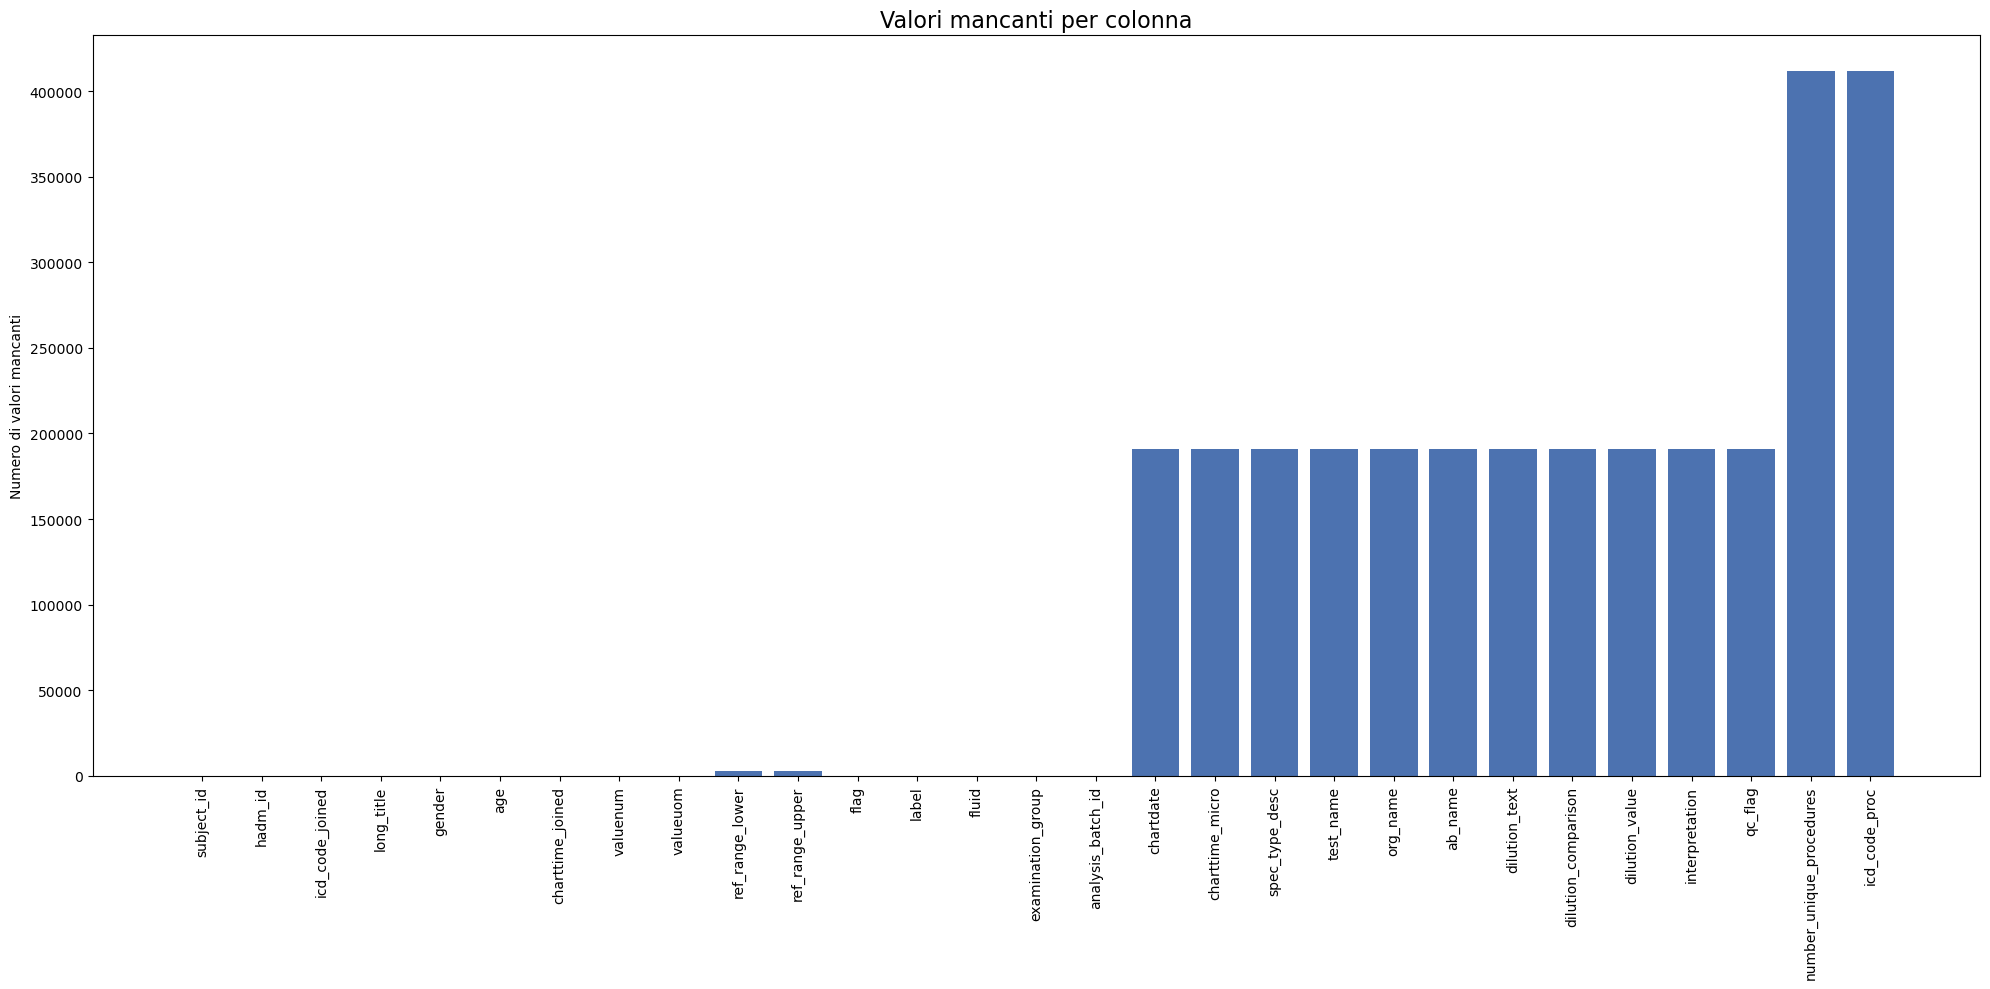

In [44]:

plt.figure(figsize=(20,10))

# Conteggio dei NaN per colonna
missing_counts = joined_df.isnull().sum()

# Barplot
plt.bar(missing_counts.index, missing_counts.values, color="#4c72b0")

plt.title("Valori mancanti per colonna", fontsize=16)
plt.ylabel("Numero di valori mancanti")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [45]:


def count_null_entries(df):
    """
    Conta quanti valori nulli (NaN) ci sono per riga
    e restituisce la distribuzione in percentuale.
    """
    # Conta i NaN per ogni riga
    null_counts = df.isnull().sum(axis=1)

    # Distribuzione: quante righe hanno 0, 1, 2... NaN
    null_percentage = null_counts.value_counts().sort_index() / len(df) * 100

    # Restituisce un dataframe riassuntivo
    return null_percentage.reset_index().rename(
        columns={'index': 'Numero di valori null per riga',
                 0: 'Percentuale righe null'}
    )

# Uso sul tuo dataset
count_null_entries(joined_df)



,Numero di valori null per riga,count
0,0,87.830206
1,2,7.849187
2,4,0.004785
3,10,0.000068
4,11,2.812518
5,13,1.500732
6,15,0.002257
7,21,0.000068
8,23,0.000181


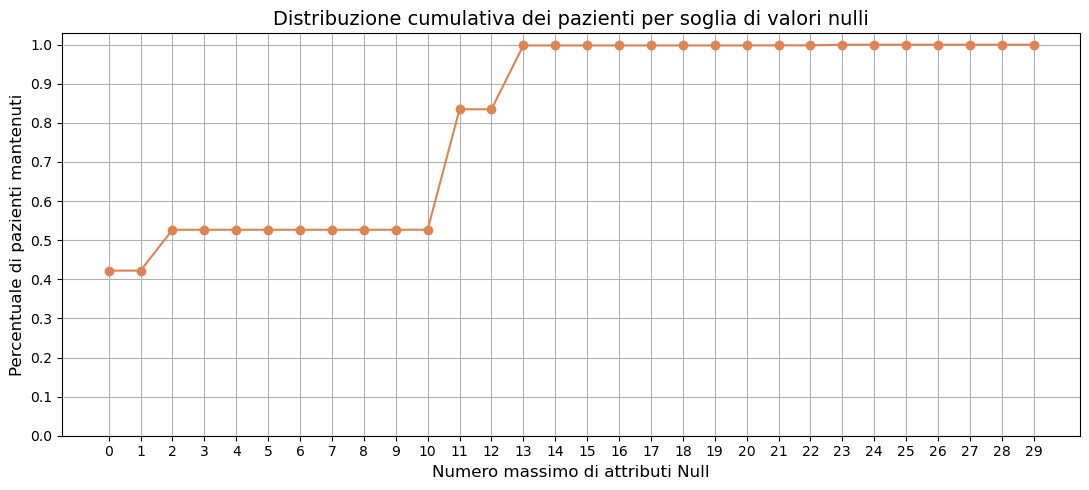

In [46]:


# Dizionario per salvare la percentuale cumulativa di pazienti
temp_pazienti = {}

# Totale pazienti unici nel dataset
totale_pazienti = joined_df["subject_id"].nunique()

# Loop su tutte le soglie da 0 a numero di colonne
for threshold in range(0, len(joined_df.columns)+1):
    # Maschera: righe con al massimo 'threshold' valori nulli
    mask = (joined_df.isnull().sum(axis=1)) <= threshold

    # Pazienti unici che rimarrebbero
    pazienti_mantenuti = joined_df[mask]["subject_id"].nunique()

    # Percentuale di pazienti mantenuti
    temp_pazienti[threshold] = pazienti_mantenuti / totale_pazienti

# Plot
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(list(temp_pazienti.keys()), list(temp_pazienti.values()), marker='o', color="#dd8452")

# Etichette e griglia
ax.set_xticks(range(0, len(joined_df.columns)+1, 1))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.grid(True)
ax.set_xlabel("Numero massimo di attributi Null", fontsize=12)
ax.set_ylabel("Percentuale di pazienti mantenuti", fontsize=12)
ax.set_title("Distribuzione cumulativa dei pazienti per soglia di valori nulli", fontsize=14)
plt.tight_layout()
plt.show()


In [47]:
# Current threshold
threshold = 13

# Maschera: righe con più di threshold valori nulli
mask_drop = joined_df.isnull().sum(axis=1) > threshold

# Apply the mask to get the cleaned dataframe
df_cleaned = joined_df[~mask_drop]

# Pazienti TOTALI prima della pulizia
pazienti_before = joined_df["subject_id"].nunique()

# Pazienti RIMASTI dopo la pulizia
pazienti_after = df_cleaned["subject_id"].nunique()

# Pazienti PERSI completamente (non hanno più NESSUNA riga)
pazienti_persi = pazienti_before - pazienti_after

# Percentuale sul totale
percentuale_persi = (pazienti_persi / pazienti_before) * 100

print(f"Pazienti totali prima: {pazienti_before}")
print(f"Pazienti rimasti dopo: {pazienti_after}")
print(f"Pazienti persi completamente: {pazienti_persi} ({percentuale_persi:.2f}%)")

# Info aggiuntive
righe_before = len(joined_df)
righe_after = len(df_cleaned)
righe_perse = righe_before - righe_after
print(f"\nRighe totali prima: {righe_before}")
print(f"Righe rimosse: {righe_perse} ({(righe_perse/righe_before)*100:.2f}%)")
print(f"Righe rimaste: {righe_after}")

Pazienti totali prima: 4392
Pazienti rimasti dopo: 4383
Pazienti persi completamente: 9 (0.20%)

Righe totali prima: 4430905
Righe rimosse: 111 (0.00%)
Righe rimaste: 4430794


In [48]:
def drop_rows_with_nulls(df, threshold, ignore_cols=[]):
    """
    Elimina le righe che hanno più di 'threshold' valori nulli,
    ignorando le colonne specificate in 'ignore_cols'.
    """
    cols_to_check = [col for col in df.columns if col not in ignore_cols]
    min_non_nulls = len(cols_to_check) - threshold
    df_cleaned = df.dropna(thresh=min_non_nulls, subset=cols_to_check).copy()
    return df_cleaned

joined_df = drop_rows_with_nulls(joined_df, threshold=13)

# Define fill values dictionary for efficiency
fill_values = {
    'valuenum': -1,
    'valueuom': "NO_UOM",
    'flag': -1,
    'label': "NO_LAB_LABEL",
    'fluid': "NO_FLUID",
    'examination_group': "NO_EXAM_GROUP",
    'analysis_batch_id': "NO_BATCH_ID",
    'number_unique_procedures': 0,
    'icd_code_proc': "NO_PROCEDURES"
}

# Apply all fillna operations at once
joined_df = joined_df.fillna(fill_values)

joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,ref_range_lower,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,29.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,0.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,85.80,sec,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,70.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,3.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,133.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES


In [49]:
# Filling the missing values for those who did not have a microbio test done
joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")
joined_df

#If NO_MICROBIO, fill the microbio_test fields 
micro_bio_cols = ['org_name', 'ab_name', 'dilution_text','dilution_comparison','dilution_value', 'interpretation', 'qc_flag']

micro_bio_mask = joined_df['spec_type_desc'] == "NO_MICROBIO"

#Fill orgname with NOT_ORG_DETECTED
joined_df.loc[micro_bio_mask, 'org_name'] = joined_df.loc[micro_bio_mask, 'org_name'].fillna(value = "NO_ORG_DETECTED")

#Fill test_name with NO_TEST_DONE
joined_df.loc[micro_bio_mask, 'test_name'] = joined_df.loc[micro_bio_mask, 'test_name'].fillna(value = "NO_TEST_DONE")

# Fill ab_name with NO_AB_DETECTED
joined_df.loc[micro_bio_mask, 'ab_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_AB_DETECTED")

#Fill dilution_text with "-1"
joined_df.loc[micro_bio_mask, 'dilution_text'] = joined_df.loc[micro_bio_mask, 'dilution_text'].fillna(value = "-1")

#Fill dilution_comparison with "="
joined_df.loc[micro_bio_mask, 'dilution_comparison'] = joined_df.loc[micro_bio_mask, 'dilution_comparison'].fillna(value = "=")

#Fill dilution_value with -1
joined_df.loc[micro_bio_mask, 'dilution_value'] = joined_df.loc[micro_bio_mask, 'dilution_value'].fillna(value = -1)

#Fill interpretation with NOT_INTERPRETATION
joined_df.loc[micro_bio_mask, 'interpretation'] = joined_df.loc[micro_bio_mask, 'interpretation'].fillna(value = "NO_INTERPRETATION")

#Fill qc_flag with NOT_QC_FLAG
joined_df.loc[micro_bio_mask, 'qc_flag'] = joined_df.loc[micro_bio_mask, 'qc_flag'].fillna(value = "NO_QC_FLAG")

joined_df


,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,ref_range_lower,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,198.00,IU/L,29.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,1.20,u,0.9,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75.0,2188-01-05 06:56:00,85.80,sec,25.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430901,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,143.00,mg/dL,70.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430902,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,3.90,mEq/L,3.3,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430903,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83.0,2155-11-27 10:00:00,141.00,mEq/L,133.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES


In [50]:
#normalize valuenum using the ref_range_lower and ref_range_upper:create a new column valuenum_norm
#caluate the range
range_width = joined_df['ref_range_upper'] - joined_df['ref_range_lower']
#normalize only if range_width is not zero
joined_df['valuenum_norm'] = np.where(
    range_width > 0,
    (joined_df['valuenum'] - joined_df['ref_range_lower']) / range_width,
     np.nan 
)

#drop ref_range_lower and ref_range_upper
joined_df = joined_df.drop(columns=['ref_range_lower', 'ref_range_upper'])


## Correlation between the cols

In [51]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[numeric_cols].corr("pearson")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures,valuenum_norm
icd_code_joined,1.000000,-0.013864,0.247690,-0.006514,0.019105,0.057431,-0.188004,-0.040306
gender,-0.013864,1.000000,0.117171,0.004338,-0.024585,0.049098,-0.074359,0.005282
age,0.247690,0.117171,1.000000,-0.000653,0.031032,0.066693,-0.120184,-0.003749
valuenum,-0.006514,0.004338,-0.000653,1.000000,0.023105,-0.000421,0.010700,0.033981
flag,0.019105,-0.024585,0.031032,0.023105,1.000000,0.007172,0.084057,0.050890
dilution_value,0.057431,0.049098,0.066693,-0.000421,0.007172,1.000000,-0.042192,-0.001437
number_unique_procedures,-0.188004,-0.074359,-0.120184,0.010700,0.084057,-0.042192,1.000000,0.022319
valuenum_norm,-0.040306,0.005282,-0.003749,0.033981,0.050890,-0.001437,0.022319,1.000000


In [52]:
# Kendall correlation
joined_df[numeric_cols].corr("kendall")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures,valuenum_norm
icd_code_joined,1.000000,0.009564,0.353783,0.000350,0.015388,0.043862,-0.199136,-0.008500
gender,0.009564,1.000000,0.088940,-0.002884,-0.024585,0.132323,-0.085956,-0.009761
age,0.353783,0.088940,1.000000,0.004472,0.028701,0.123837,-0.116003,0.005598
valuenum,0.000350,-0.002884,0.004472,1.000000,-0.034357,0.002741,0.004265,0.097170
flag,0.015388,-0.024585,0.028701,-0.034357,1.000000,0.016245,0.067691,0.108312
dilution_value,0.043862,0.132323,0.123837,0.002741,0.016245,1.000000,0.028347,-0.006268
number_unique_procedures,-0.199136,-0.085956,-0.116003,0.004265,0.067691,0.028347,1.000000,0.012991
valuenum_norm,-0.008500,-0.009761,0.005598,0.097170,0.108312,-0.006268,0.012991,1.000000


In [53]:
# Spearman correlation
joined_df[numeric_cols].corr("spearman")

,icd_code_joined,gender,age,valuenum,flag,dilution_value,number_unique_procedures,valuenum_norm
icd_code_joined,1.000000,0.010642,0.505658,0.000461,0.017124,0.052657,-0.253769,-0.011480
gender,0.010642,1.000000,0.101765,-0.003527,-0.024585,0.140772,-0.102057,-0.011937
age,0.505658,0.101765,1.000000,0.006246,0.032840,0.149817,-0.170575,0.007656
valuenum,0.000461,-0.003527,0.006246,1.000000,-0.042022,0.003561,0.006128,0.117463
flag,0.017124,-0.024585,0.032840,-0.042022,1.000000,0.017283,0.080370,0.132459
dilution_value,0.052657,0.140772,0.149817,0.003561,0.017283,1.000000,0.035617,-0.008175
number_unique_procedures,-0.253769,-0.102057,-0.170575,0.006128,0.080370,0.035617,1.000000,0.018933
valuenum_norm,-0.011480,-0.011937,0.007656,0.117463,0.132459,-0.008175,0.018933,1.000000


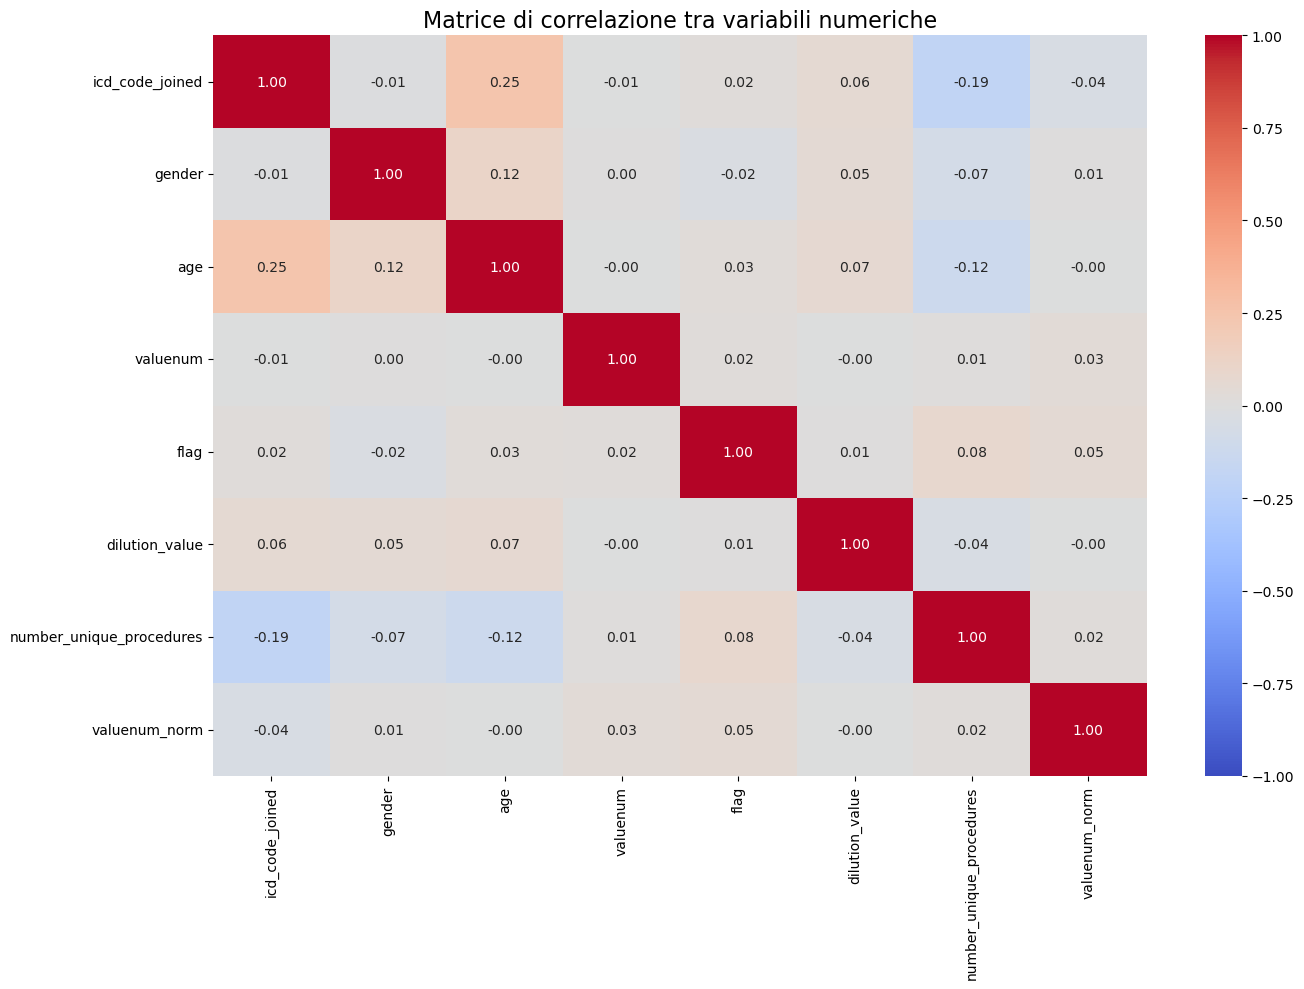

In [54]:
# Seleziona solo le colonne numeriche
df_num = joined_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = df_num.corr()

# Plot della heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra variabili numeriche", fontsize=16)
plt.tight_layout()
plt.show()


# Feature creation

In [55]:
# Creating the new features representing the profiles of the patients
#Taking the common attributes (subject_id,hadm_id, gender, age, ICD)
profile_cols = ['subject_id', 'hadm_id', 'gender', 'age']
profile_df = joined_df[profile_cols].drop_duplicates().reset_index(drop=True)

In [56]:
# Dropping duplicates based on the cols that makes a lab event unique
lab_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_joined', 'label'])

#number of hammission
hadm_count=profile_df[['subject_id', 'hadm_id']].drop_duplicates().groupby('subject_id')['hadm_id'].size().reset_index(name='number_of_hadm')
# Dropping duplicates based on the cols that makes a lab event unique
profile_df = pd.merge(profile_df, hadm_count, on='subject_id', how='left')


# === LAB PROFILE FEATURES === #

#Creating the feature for the lab events, if "NO_LAB_LABEL" then count is 0
lab_event_counts = lab_uniq[lab_uniq['label'] != "NO_LAB_LABEL"].groupby(['subject_id', 'hadm_id'])['label'].count().reset_index()
lab_event_counts = lab_event_counts.rename(columns={'label': 'lab_event_count'})

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['lab_event_count'] = profile_df['lab_event_count'].fillna(0)
abnormal_lab_event_counts = lab_uniq[lab_uniq['flag'] == 1].groupby(['subject_id', 'hadm_id'])['flag'].count().reset_index()
abnormal_lab_event_counts = abnormal_lab_event_counts.rename(columns={'flag': 'abnormal_lab_event_count'})
profile_df = pd.merge(profile_df, abnormal_lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['abnormal_lab_event_count'] = profile_df['abnormal_lab_event_count'].fillna(0)
profile_df




,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count
0,10000980,29654838,1,75.0,2,44.0,18.0
1,10000980,26913865,1,75.0,2,124.0,51.0
2,10002013,24760295,1,69.0,1,40.0,15.0
3,10002155,23822395,1,69.0,1,276.0,106.0
4,10004457,28723315,0,66.0,1,20.0,6.0
...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,1,0.0,0.0
4849,19998597,23720781,1,57.0,1,0.0,0.0
4850,19998598,26940500,1,69.0,1,0.0,0.0
4851,19998599,20343031,0,59.0,1,0.0,0.0


In [57]:
# === MICROBIO PROFILE FEATURES === #

# Dropping duplicates based on the cols that makes a microbio event unique
microbio_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_micro', 'spec_type_desc', 'org_name', 'ab_name'])

#Counting the number of microbio tests done per subject_id and hadm_id, if "NO_MICROBIO" then count is 0, using microbio_uniq
# Deduplicazione mirata sugli eventi microbiologici
microbio_test_counts = microbio_uniq[microbio_uniq['spec_type_desc'] != "NO_MICROBIO"].groupby(['subject_id', 'hadm_id'])['spec_type_desc'].nunique().reset_index()
microbio_test_counts = microbio_test_counts.rename(columns={'spec_type_desc': 'microbio_test_count'})

# Merge nel profilo paziente
profile_df = pd.merge(profile_df, microbio_test_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['microbio_test_count'] = profile_df['microbio_test_count'].fillna(0)

# Counting the number of unique microorganisms detected per subject_id and hadm_id, if "NO_ORG_DETECTED" then count is 0, useing microbio_uniq
microbio_counts = microbio_uniq[microbio_uniq['org_name'] != "NO_ORG_DETECTED"].groupby(['subject_id', 'hadm_id'])['org_name'].nunique().reset_index()
microbio_counts = microbio_counts.rename(columns={'org_name': 'unique_microorganisms_count'})
profile_df = pd.merge(profile_df, microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_microorganisms_count'] = profile_df['unique_microorganisms_count'].fillna(0)

resistant_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "R") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="resistant_microorganisms_count")
)
profile_df = pd.merge(profile_df, resistant_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['resistant_microorganisms_count'] = profile_df['resistant_microorganisms_count'].fillna(0)

intermediate_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "I") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="intermediate_microorganisms_count")
)
profile_df = pd.merge(profile_df, intermediate_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['intermediate_microorganisms_count'] = profile_df['intermediate_microorganisms_count'].fillna(0)

sensitive_microbio_counts = (
    microbio_uniq[(microbio_uniq["interpretation"] == "S") & (microbio_uniq["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="sensitive_microorganisms_count")
)
profile_df = pd.merge(profile_df, sensitive_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['sensitive_microorganisms_count'] = profile_df['sensitive_microorganisms_count'].fillna(0)
#numero di antibiotici diversi testati
ab_count=microbio_uniq[microbio_uniq['ab_name'] != "NO_AB_DETECTED"].groupby(['subject_id', 'hadm_id'])['ab_name'].nunique().reset_index()
ab_count = ab_count.rename(columns={'ab_name': 'unique_antibiotics_count'})
profile_df = pd.merge(profile_df, ab_count, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_antibiotics_count'] = profile_df['unique_antibiotics_count'].fillna(0)



profile_df

,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,resistant_microorganisms_count,intermediate_microorganisms_count,sensitive_microorganisms_count,unique_antibiotics_count
0,10000980,29654838,1,75.0,2,44.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0
1,10000980,26913865,1,75.0,2,124.0,51.0,1.0,0.0,0.0,0.0,0.0,0.0
2,10002013,24760295,1,69.0,1,40.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0
3,10002155,23822395,1,69.0,1,276.0,106.0,4.0,0.0,0.0,0.0,0.0,0.0
4,10004457,28723315,0,66.0,1,20.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4849,19998597,23720781,1,57.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4850,19998598,26940500,1,69.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4851,19998599,20343031,0,59.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [58]:
# === PROCEDURE PROFILE FEATURES === #
# Dropping duplicates based on the cols that makes a procedure event unique
procedure_uniq = joined_df.drop_duplicates(subset=['subject_id', 'hadm_id','icd_code_proc'])

# Count the number of unique procedures (splitting comma-separated codes) per subject_id and hadm_id
# If "NO_PROCEDURES" then count is 0
procedure_counts = (
    procedure_uniq[procedure_uniq['icd_code_proc'] != "NO_PROCEDURES"]
    .groupby(['subject_id', 'hadm_id'])['icd_code_proc']
    .apply(lambda x: sum(len(proc.split(',')) for proc in x))
    .reset_index(name='unique_procedures_count')
)

# Merge with profile_df
profile_df = pd.merge(profile_df, procedure_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_procedures_count'] = profile_df['unique_procedures_count'].fillna(0)
profile_df


# == SOME INDICATORS ==
#I choose as indicators values with more occurrences and clinical relevance
#for each examination group evaluet also the correlation matrix to choose the most representative exams

features = {}
for exam in ["Glucose","Potassium","Sodium","Creatinine","Bicarbonate","Calcium, Total","Urea Nitrogen","Creatinine","Troponin T","NTproBNP","PTT","INR(PT)","Hemoglobin","WBC Count","Platelet Count","White Blood Cells"]:
    feat = (
        lab_uniq[lab_uniq['label'] == exam]
        .groupby(['subject_id','hadm_id'])['valuenum_norm']
        .max()
        .reset_index()
        .rename(columns={'valuenum_norm': f"max_{exam.lower()}"})
    )
    features[exam] = feat

# Merge finale
for feat in features.values():
    profile_df = profile_df.merge(feat, on=['subject_id','hadm_id'], how='left')

# Riempimento dei NaN
profile_df = profile_df.fillna(0)

# Removes all the counts columns used for calculations
#cols = profile_df.columns
#counts_cols = [col for col in cols if 'count' in col and col not in ['subject_id', 'hadm_id']]
#profile_df = profile_df.drop(columns=counts_cols)

# Remove duplicates (just in case)
profile_df = profile_df.drop_duplicates().reset_index(drop=True)
profile_df


,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,resistant_microorganisms_count,...,"max_calcium, total",max_urea nitrogen,max_troponin t,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells
0,10000980,29654838,1,75.0,2,44.0,18.0,0.0,0.0,0.0,...,0.526316,1.785714,4.0,0.0,5.286957,1.5,-0.525,0.0,0.162069,0.128571
1,10000980,26913865,1,75.0,2,124.0,51.0,1.0,0.0,0.0,...,0.684211,3.428571,15.0,0.0,3.878261,2.0,-0.475,0.0,0.251724,0.328571
2,10002013,24760295,1,69.0,1,40.0,15.0,0.0,0.0,0.0,...,-0.052632,0.928571,13.0,0.0,4.634783,0.5,0.025,0.0,0.389655,0.714286
3,10002155,23822395,1,69.0,1,276.0,106.0,4.0,0.0,0.0,...,0.277778,1.071429,399.0,0.0,5.661538,10.5,0.125,0.0,0.341379,0.500000
4,10004457,28723315,0,66.0,1,20.0,6.0,0.0,0.0,0.0,...,0.421053,0.714286,0.0,0.0,0.000000,0.0,-0.075,0.0,0.396552,0.357143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000,0.0,0.000000,0.000000
4849,19998597,23720781,1,57.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000,0.0,0.000000,0.000000
4850,19998598,26940500,1,69.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000,0.0,0.000000,0.000000
4851,19998599,20343031,0,59.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000,0.0,0.000000,0.000000


Numero totale di ICD distinti (escludendo NaN): 20

ICD code : occorrenze (righe)
20: 2723
21: 1255632
22: 3335
24: 4183
25: 235848
30: 73383
31: 206636
33: 141031
34: 33261
35: 217398
36: 944
40: 23175
42: 101766
44: 23116
45: 4092
46: 713
47: 159354
48: 186970
49: 54654
50: 1702580


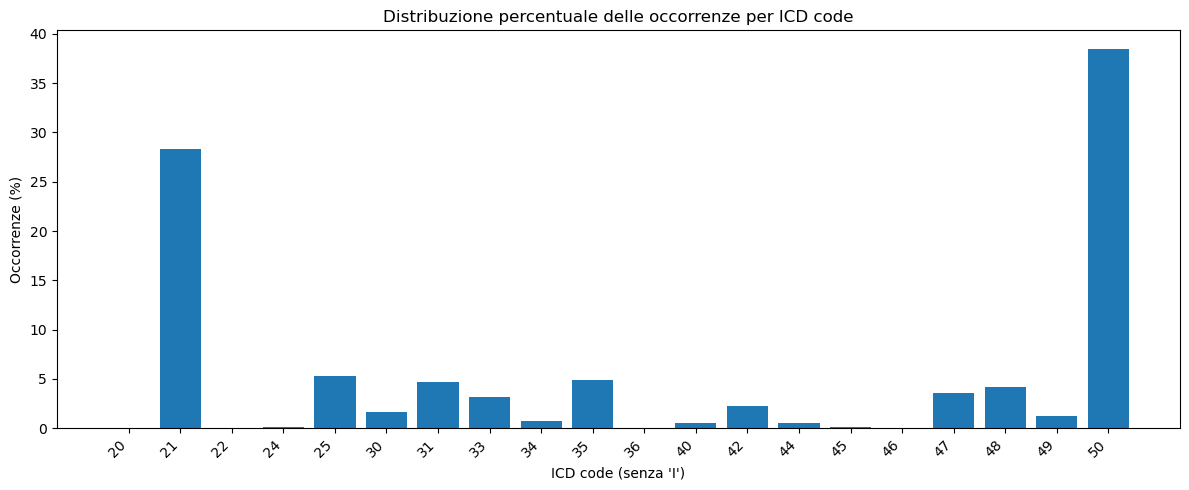

In [59]:
# Conteggio delle occorrenze per ogni codice ICD (esclude NaN) e grafico
icd_counts = joined_df['icd_code_joined'].dropna().value_counts().sort_index()

print(f"Numero totale di ICD distinti (escludendo NaN): {icd_counts.size}")
print("\nICD code : occorrenze (righe)")
for code, cnt in icd_counts.items():
    print(f"{code}: {cnt}")

icd_perc = (icd_counts / icd_counts.sum()) * 100

plt.figure(figsize=(12, 5))
plt.bar(icd_perc.index.astype(str), icd_perc.values)
plt.xlabel("ICD code (senza 'I')")
plt.ylabel("Occorrenze (%)")
plt.title("Distribuzione percentuale delle occorrenze per ICD code")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##### Aggregazione degli ICD-code in macro-categorie 
Nel dataset sono presenti diversi codici ICD-code relativi a patologie cardiache (I20–I50).  
Per evitare di portarci dietro una colonna binaria per ciascun ICD (con molte feature sparse e poco informative), abbiamo deciso di raggruppare i codici in 9 macro-categorie clinicamente coerenti.  

Per ogni paziente (considerando tutte le sue ammissioni), costruiamo quindi 9 feature binarie: ciascuna feature vale 1 se il paziente presenta almeno un ICD appartenente a quella categoria, altrimenti 0.

### Feature finali (9 colonne)

- ACS_acute_ischemic = 1 se ha uno tra I20, I21, I22, I24
- Chronic_ischemic = 1 se ha I25
- Heart_failure = 1 se ha I50
- Valvular_nonrheumatic = 1 se ha uno tra I34, I35, I36
- Myocarditis_or_cardiomyopathy = 1 se ha uno tra I40, I42
- Pericardial_disease = 1 se ha uno tra I30, I31
- Endocarditis = 1 se ha I33
- Cardiac_arrest = 1 se ha I46
- Arrhythmias_or_conduction = 1 se ha uno tra I44, I45, I47, I48, I49


In [60]:
# =============================================================================
# ICD MACRO FEATURES (9 colonne) — da icd_code_joined (20..50)
# =============================================================================

ICD_MACRO_MAP = {
    # Ischemic
    20: "ACS_acute_ischemic",
    21: "ACS_acute_ischemic",
    22: "ACS_acute_ischemic",
    24: "ACS_acute_ischemic",
    25: "Chronic_ischemic",

    # Heart failure
    50: "Heart_failure",

    # Structural / inflammatory
    34: "Valvular_nonrheumatic",
    35: "Valvular_nonrheumatic",
    36: "Valvular_nonrheumatic",
    40: "Myocarditis_or_cardiomyopathy",
    42: "Myocarditis_or_cardiomyopathy",
    30: "Pericardial_disease",
    31: "Pericardial_disease",
    33: "Endocarditis",

    # Arrest
    46: "Cardiac_arrest",

    # Arrhythmias / conduction (tutto insieme)
    44: "Arrhythmias_or_conduction",
    45: "Arrhythmias_or_conduction",
    47: "Arrhythmias_or_conduction",
    48: "Arrhythmias_or_conduction",
    49: "Arrhythmias_or_conduction",
}

ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

icd_tmp = joined_df[["subject_id", "hadm_id", "icd_code_joined"]].drop_duplicates()
icd_tmp = icd_tmp.dropna(subset=["icd_code_joined"]).copy()

icd_tmp["icd_code_joined"] = pd.to_numeric(icd_tmp["icd_code_joined"], errors="coerce").astype("Int64")
icd_tmp["icd_group"] = icd_tmp["icd_code_joined"].map(ICD_MACRO_MAP)
icd_tmp = icd_tmp.dropna(subset=["icd_group"])

icd_macro = (
    pd.crosstab([icd_tmp["subject_id"], icd_tmp["hadm_id"]], icd_tmp["icd_group"])
      .clip(upper=1)
      .reset_index()
)

profile_df = pd.merge(profile_df, icd_macro, on=["subject_id", "hadm_id"], how="left")

for col in ICD_MACRO_COLS:
    if col not in profile_df.columns:
        profile_df[col] = 0
profile_df[ICD_MACRO_COLS] = profile_df[ICD_MACRO_COLS].fillna(0).astype(int)

# opzionale ma consigliato: rimuove la colonna ICD singola ora che hai le macro-feature
if "icd_code_joined" in profile_df.columns:
    profile_df = profile_df.drop(columns=["icd_code_joined"])

profile_df


,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,microbio_test_count,unique_microorganisms_count,resistant_microorganisms_count,...,max_white blood cells,ACS_acute_ischemic,Arrhythmias_or_conduction,Cardiac_arrest,Chronic_ischemic,Endocarditis,Heart_failure,Myocarditis_or_cardiomyopathy,Pericardial_disease,Valvular_nonrheumatic
0,10000980,29654838,1,75.0,2,44.0,18.0,0.0,0.0,0.0,...,0.128571,0,0,0,0,0,1,0,0,0
1,10000980,26913865,1,75.0,2,124.0,51.0,1.0,0.0,0.0,...,0.328571,1,0,0,0,0,0,0,0,0
2,10002013,24760295,1,69.0,1,40.0,15.0,0.0,0.0,0.0,...,0.714286,1,0,0,0,0,0,0,0,0
3,10002155,23822395,1,69.0,1,276.0,106.0,4.0,0.0,0.0,...,0.500000,1,0,0,0,0,0,0,0,0
4,10004457,28723315,0,66.0,1,20.0,6.0,0.0,0.0,0.0,...,0.357143,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,1,71.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0,1,0,0,0,0,0,0,0
4849,19998597,23720781,1,57.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0,0,0,0,0,0,0,1,0
4850,19998598,26940500,1,69.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0,1,0,0,0,0,0,0,0
4851,19998599,20343031,0,59.0,1,0.0,0.0,0.0,0.0,0.0,...,0.000000,0,0,0,0,0,0,0,1,0


### RIGUARDARE LE OCCORRENZE PERCHè RICONTA LE GLI STESSI ICD_CODE

Occorrenze (righe ICD) per macro-categoria:
icd_code_joined
ACS_acute_ischemic               1265873
Chronic_ischemic                  235848
Heart_failure                    1702580
Valvular_nonrheumatic             251603
Myocarditis_or_cardiomyopathy     124941
Pericardial_disease               280019
Endocarditis                      141031
Cardiac_arrest                       713
Arrhythmias_or_conduction         428186
Name: count, dtype: int64


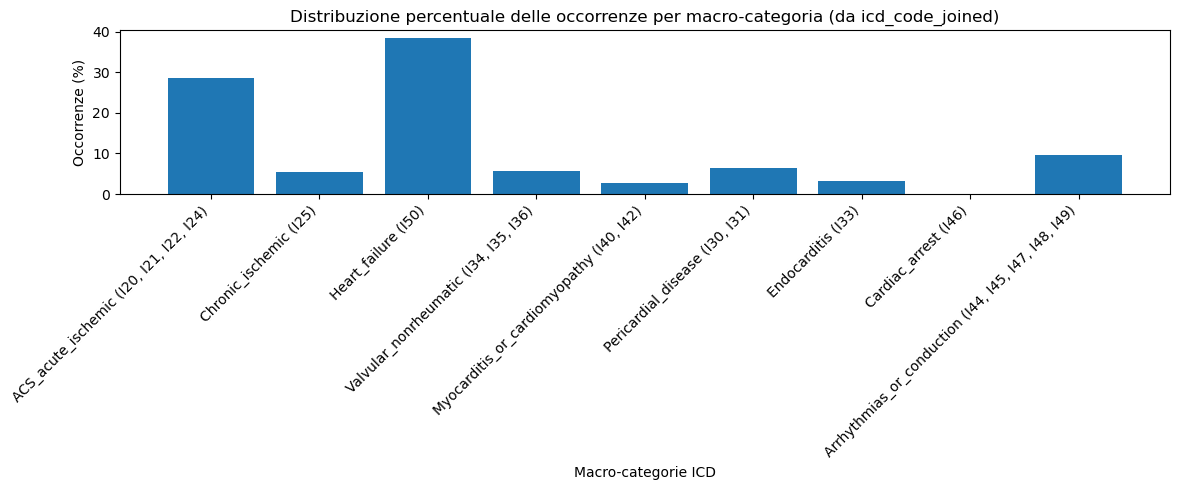

In [61]:
# Grafico: mostrare le nuova percentuale di occorrenze per macro-categoria

# Label estese
ICD_MACRO_LABELS = {
    "ACS_acute_ischemic": "ACS_acute_ischemic (I20, I21, I22, I24)",
    "Chronic_ischemic": "Chronic_ischemic (I25)",
    "Heart_failure": "Heart_failure (I50)",
    "Valvular_nonrheumatic": "Valvular_nonrheumatic (I34, I35, I36)",
    "Myocarditis_or_cardiomyopathy": "Myocarditis_or_cardiomyopathy (I40, I42)",
    "Pericardial_disease": "Pericardial_disease (I30, I31)",
    "Endocarditis": "Endocarditis (I33)",
    "Cardiac_arrest": "Cardiac_arrest (I46)",
    "Arrhythmias_or_conduction": "Arrhythmias_or_conduction (I44, I45, I47, I48, I49)",
}

# Mappo ogni riga ICD alla macro-categoria (conteggio occorrenze = righe, come gli originali)
codes = pd.to_numeric(joined_df["icd_code_joined"], errors="coerce").astype("Int64")
groups = codes.map(ICD_MACRO_MAP).dropna()

# Conteggi per macro-categoria (ordine fisso)
macro_counts = groups.value_counts().reindex(ICD_MACRO_COLS, fill_value=0)

print("Occorrenze (righe ICD) per macro-categoria:")
print(macro_counts)

# Percentuali
macro_perc = (macro_counts / macro_counts.sum()) * 100
x_labels = [ICD_MACRO_LABELS[c] for c in ICD_MACRO_COLS]

plt.figure(figsize=(12, 5))
plt.bar(range(len(ICD_MACRO_COLS)), macro_perc.values)
plt.xticks(range(len(ICD_MACRO_COLS)), x_labels, rotation=45, ha="right")
plt.ylabel("Occorrenze (%)")
plt.xlabel("Macro-categorie ICD")
plt.title("Distribuzione percentuale delle occorrenze per macro-categoria (da icd_code_joined)")
plt.tight_layout()
plt.show()


In [62]:
# Aggregazione finale per subject_id 

agg_dict = {col: "max" for col in ICD_MACRO_COLS}

agg_dict.update({
    "number_of_hadm": "first",
    "gender": "first",
    "age": "first",
    "lab_event_count": "sum",
    "abnormal_lab_event_count": "sum",
    "microbio_test_count": "sum",
    "unique_microorganisms_count": "sum",
    "resistant_microorganisms_count": "sum",
    "intermediate_microorganisms_count": "sum",
    "sensitive_microorganisms_count": "sum",
    "unique_antibiotics_count": "sum",
    "unique_procedures_count": "sum",
    "max_glucose": "max",
    'max_potassium': 'max',
    'max_sodium': 'max',
    'max_creatinine': 'max',
    'max_bicarbonate': 'max',
    'max_calcium, total': 'max',
    'max_urea nitrogen': 'max',
    'max_troponin t': 'max',
    'max_ntprobnp': 'max',
    'max_ptt': 'max',
    'max_inr(pt)': 'max',
    'max_hemoglobin': 'max',
    'max_wbc count': 'max',
    'max_platelet count': 'max', 
    'max_white blood cells': 'max'
})

profile_df = profile_df.groupby("subject_id").agg(agg_dict).reset_index()
profile_df.drop_duplicates(inplace=True)
#salva the profile_df
profile_df.to_csv("../../data/processed/patient_profile.csv", index=False)
profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,"max_calcium, total",max_urea nitrogen,max_troponin t,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells
0,10000980,1,0,1,0,0,0,0,0,0,...,0.684211,3.428571,15.0,0.0,5.286957,2.0,-0.475000,0.0,0.251724,0.328571
1,10002013,1,0,0,0,0,0,0,0,0,...,-0.052632,0.928571,13.0,0.0,4.634783,0.5,0.025000,0.0,0.389655,0.714286
2,10002155,1,0,0,0,0,0,0,0,0,...,0.277778,1.071429,399.0,0.0,5.661538,10.5,0.125000,0.0,0.341379,0.500000
3,10004457,0,0,0,1,0,0,0,0,0,...,0.421053,0.714286,0.0,0.0,0.000000,0.0,-0.075000,0.0,0.396552,0.357143
4,10007058,1,0,0,0,0,0,0,0,0,...,0.473684,0.500000,277.0,0.0,4.582609,1.5,-0.315789,0.0,0.220000,1.416667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000


In [63]:


# Abnormal lab ratio
profile_df["abnormal_lab_event_ratio"] = np.where(
    profile_df["lab_event_count"] > 0,
    profile_df["abnormal_lab_event_count"] / profile_df["lab_event_count"],
    0.0
)

# Microbio ratios (evita divisione per zero)
den = profile_df["unique_microorganisms_count"].replace(0, np.nan)

profile_df["resistant_microorganism_ratio"] = (
    profile_df["resistant_microorganisms_count"] / den
).fillna(0.0)

profile_df["intermediate_microorganism_ratio"] = (
    profile_df["intermediate_microorganisms_count"] / den
).fillna(0.0)

profile_df["sensitive_microorganism_ratio"] = (
    profile_df["sensitive_microorganisms_count"] / den
).fillna(0.0)

# per tenere SOLO i ratio e non i conteggi di R/I/S
cols_drop = [
    "resistant_microorganisms_count",
    "intermediate_microorganisms_count",
    "sensitive_microorganisms_count",
]
profile_df = profile_df.drop(columns=[c for c in cols_drop if c in profile_df.columns], errors="ignore")


profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


# Visual exploration of the new features


In [64]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 38 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subject_id                        4383 non-null   int64  
 1   ACS_acute_ischemic                4383 non-null   int64  
 2   Chronic_ischemic                  4383 non-null   int64  
 3   Heart_failure                     4383 non-null   int64  
 4   Valvular_nonrheumatic             4383 non-null   int64  
 5   Myocarditis_or_cardiomyopathy     4383 non-null   int64  
 6   Pericardial_disease               4383 non-null   int64  
 7   Endocarditis                      4383 non-null   int64  
 8   Cardiac_arrest                    4383 non-null   int64  
 9   Arrhythmias_or_conduction         4383 non-null   int64  
 10  number_of_hadm                    4383 non-null   int64  
 11  gender                            4383 non-null   int64  
 12  age   

In [65]:
# Conversione in stringa (più comune)
profile_df['subject_id'] = profile_df['subject_id'].astype(object)
#profile_df['hadm_id'] = profile_df['hadm_id'].astype(object)
#profile_df['glucose_trend']=profile_df['glucose_trend'].astype(float)

In [66]:
profile_df.describe()

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,number_of_hadm,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
count,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,...,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000
mean,0.326032,0.143737,0.295460,0.061373,0.011180,0.052475,0.008670,0.000456,0.149669,1.107232,...,3.074215,3.623603,-0.169052,0.000562,0.382226,0.950230,0.365304,0.042254,0.015772,0.076001
std,0.468813,0.350863,0.456301,0.240042,0.105153,0.223009,0.092718,0.021359,0.356788,0.374812,...,3.577860,5.922615,0.476858,0.025359,0.380911,1.054411,0.153013,0.190381,0.115299,0.256235
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,-0.434783,-0.500000,-1.875000,-0.285714,-0.476000,-0.385714,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.339130,0.500000,-0.475000,0.000000,0.128000,0.428571,0.266667,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,1.234783,1.500000,-0.125000,0.000000,0.313793,0.757143,0.371542,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,5.053846,4.000000,0.150000,0.000000,0.544828,1.228571,0.475410,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,...,10.869565,109.500000,1.684211,1.400000,4.089655,38.483333,1.000000,1.000000,1.000000,1.000000


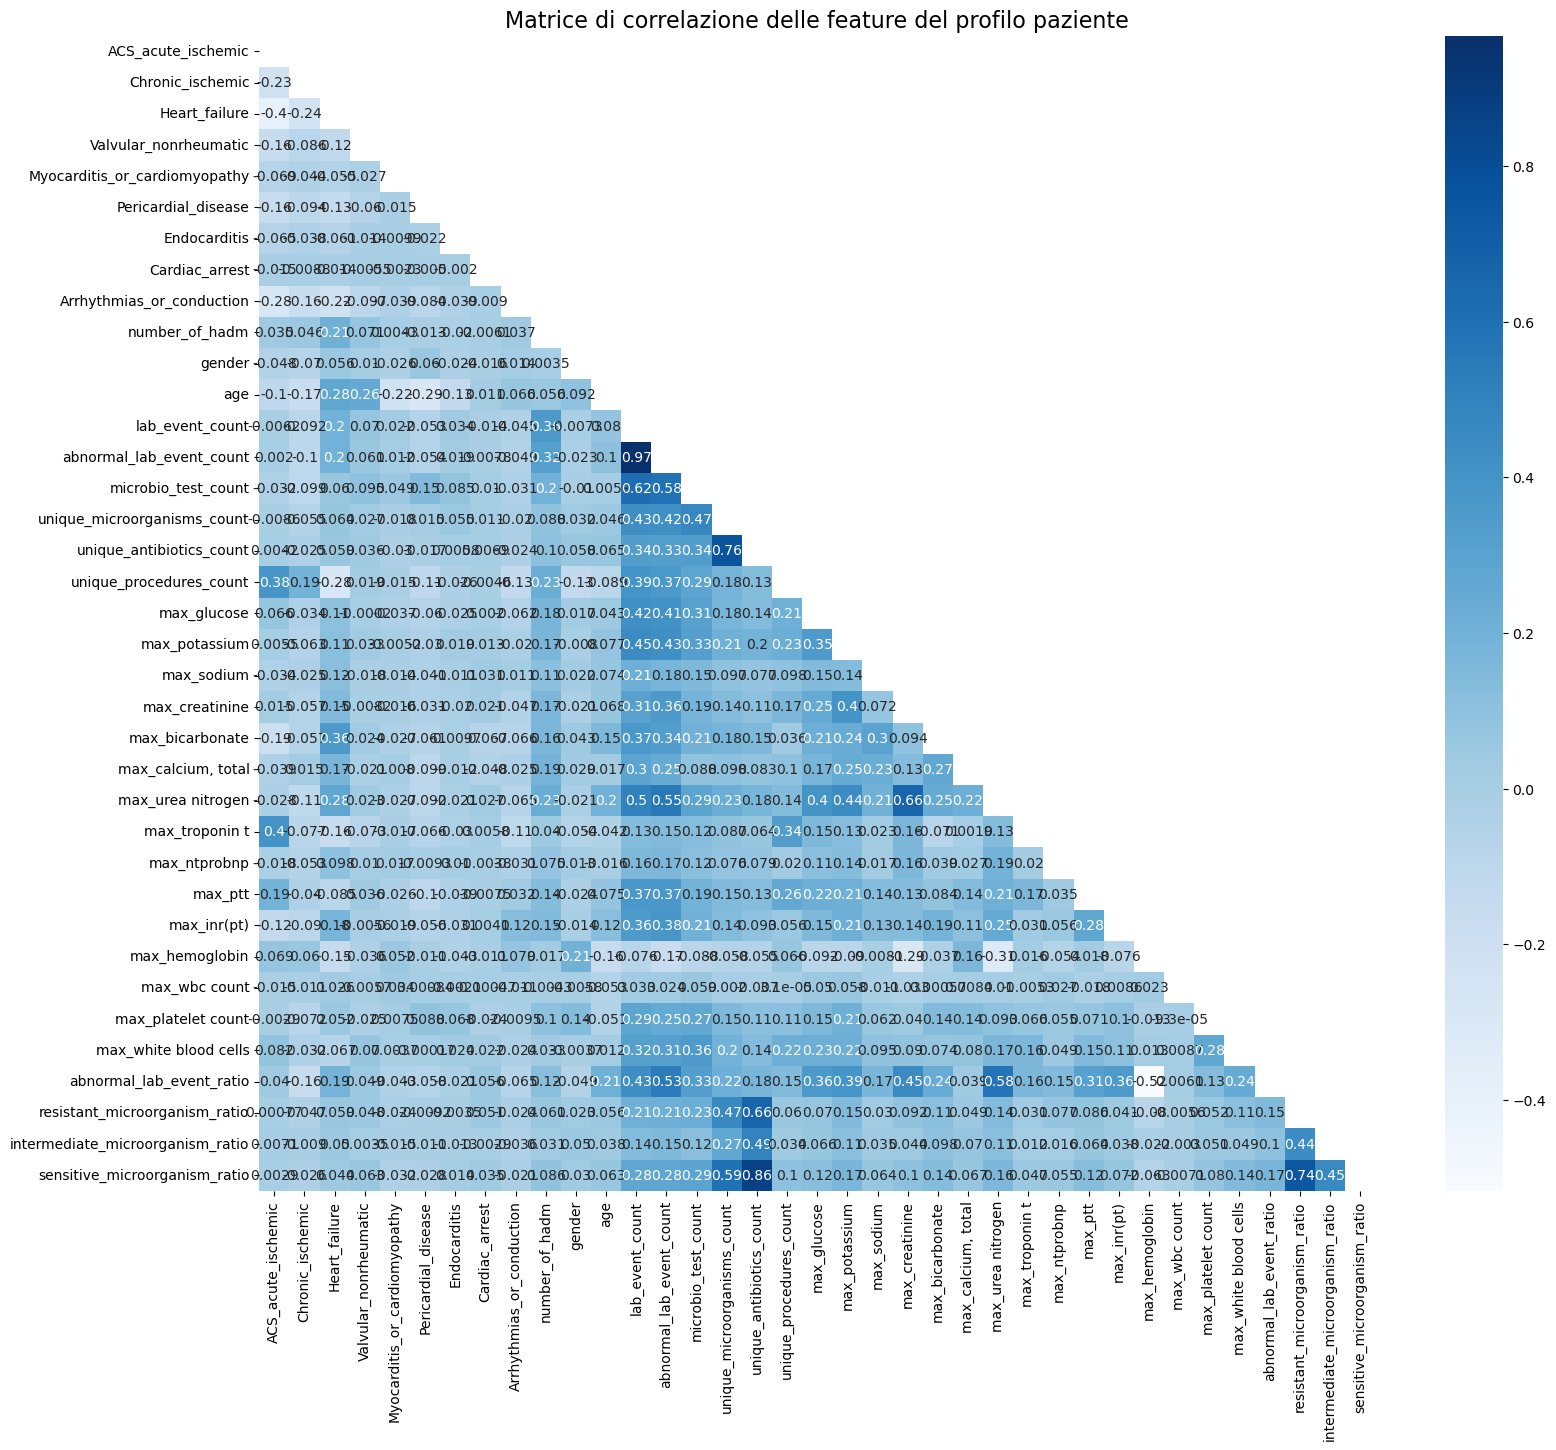

In [67]:
#correletion
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = profile_num.corr()

# Maschera triangolare superiore
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot
plt.figure(figsize=(18,15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', mask=mask)
plt.title("Matrice di correlazione delle feature del profilo paziente", fontsize=16)
plt.show()

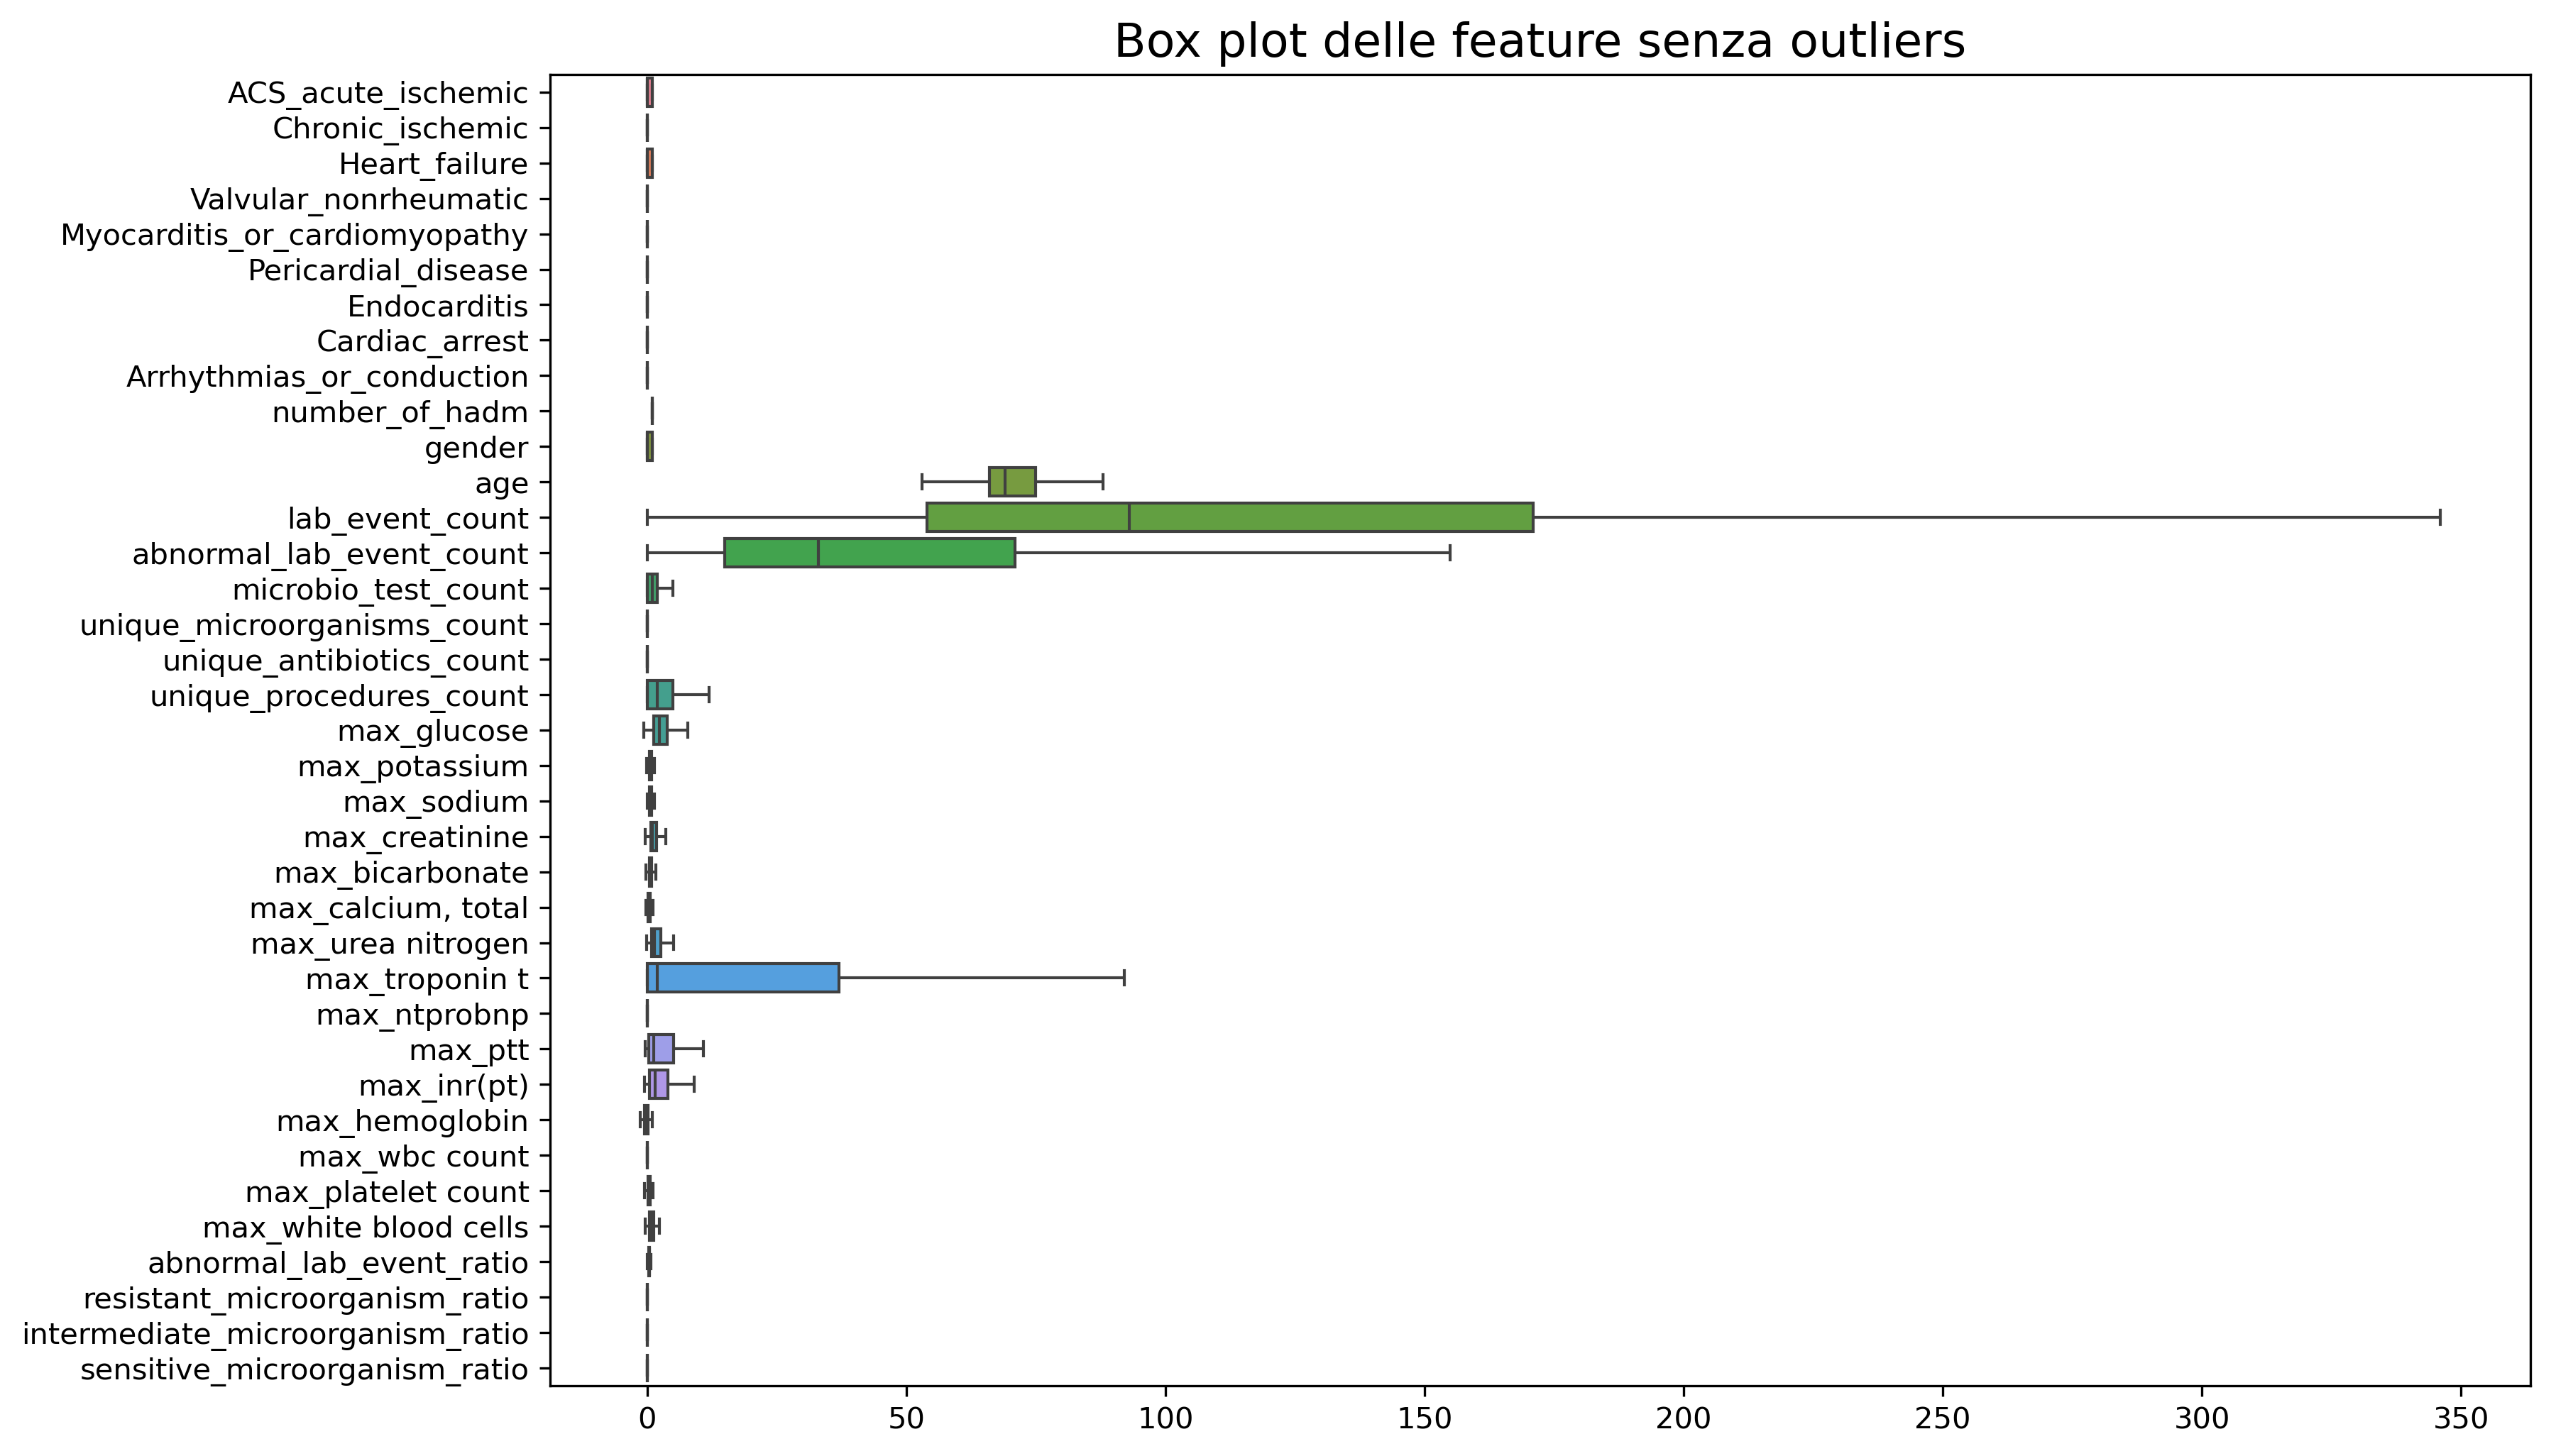

In [68]:
plt.figure(figsize=(12,8), dpi=300)
sns.boxplot(data=profile_num, orient="h", showfliers=False)
plt.title("Box plot delle feature senza outliers", fontsize=16)
plt.show()

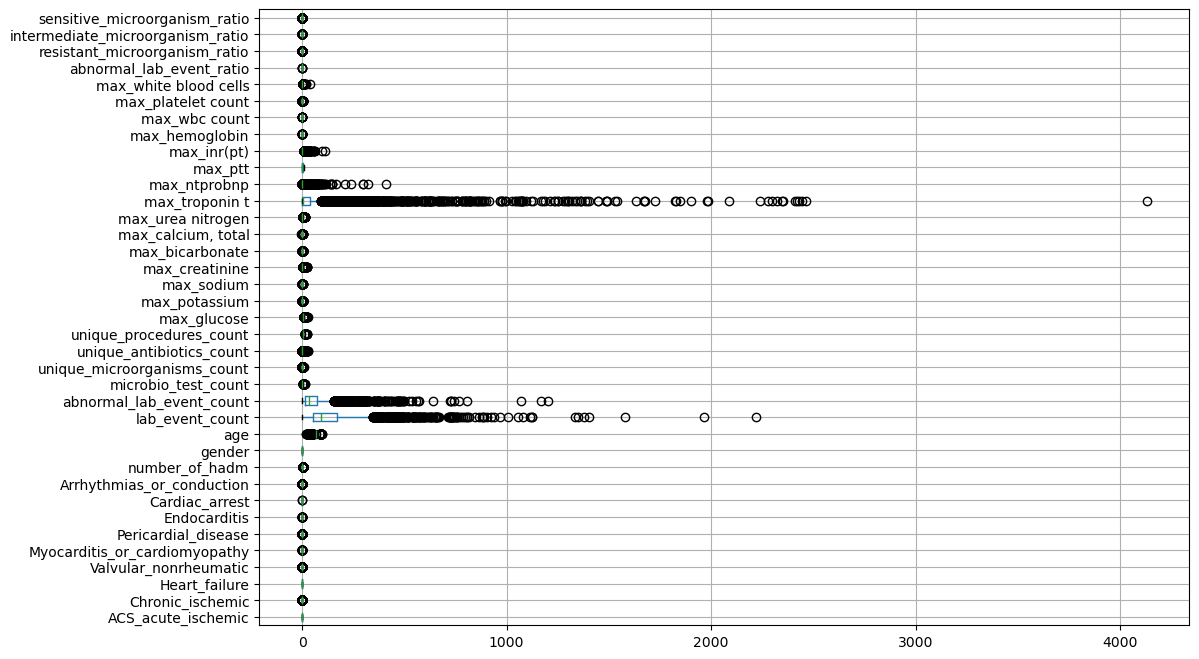

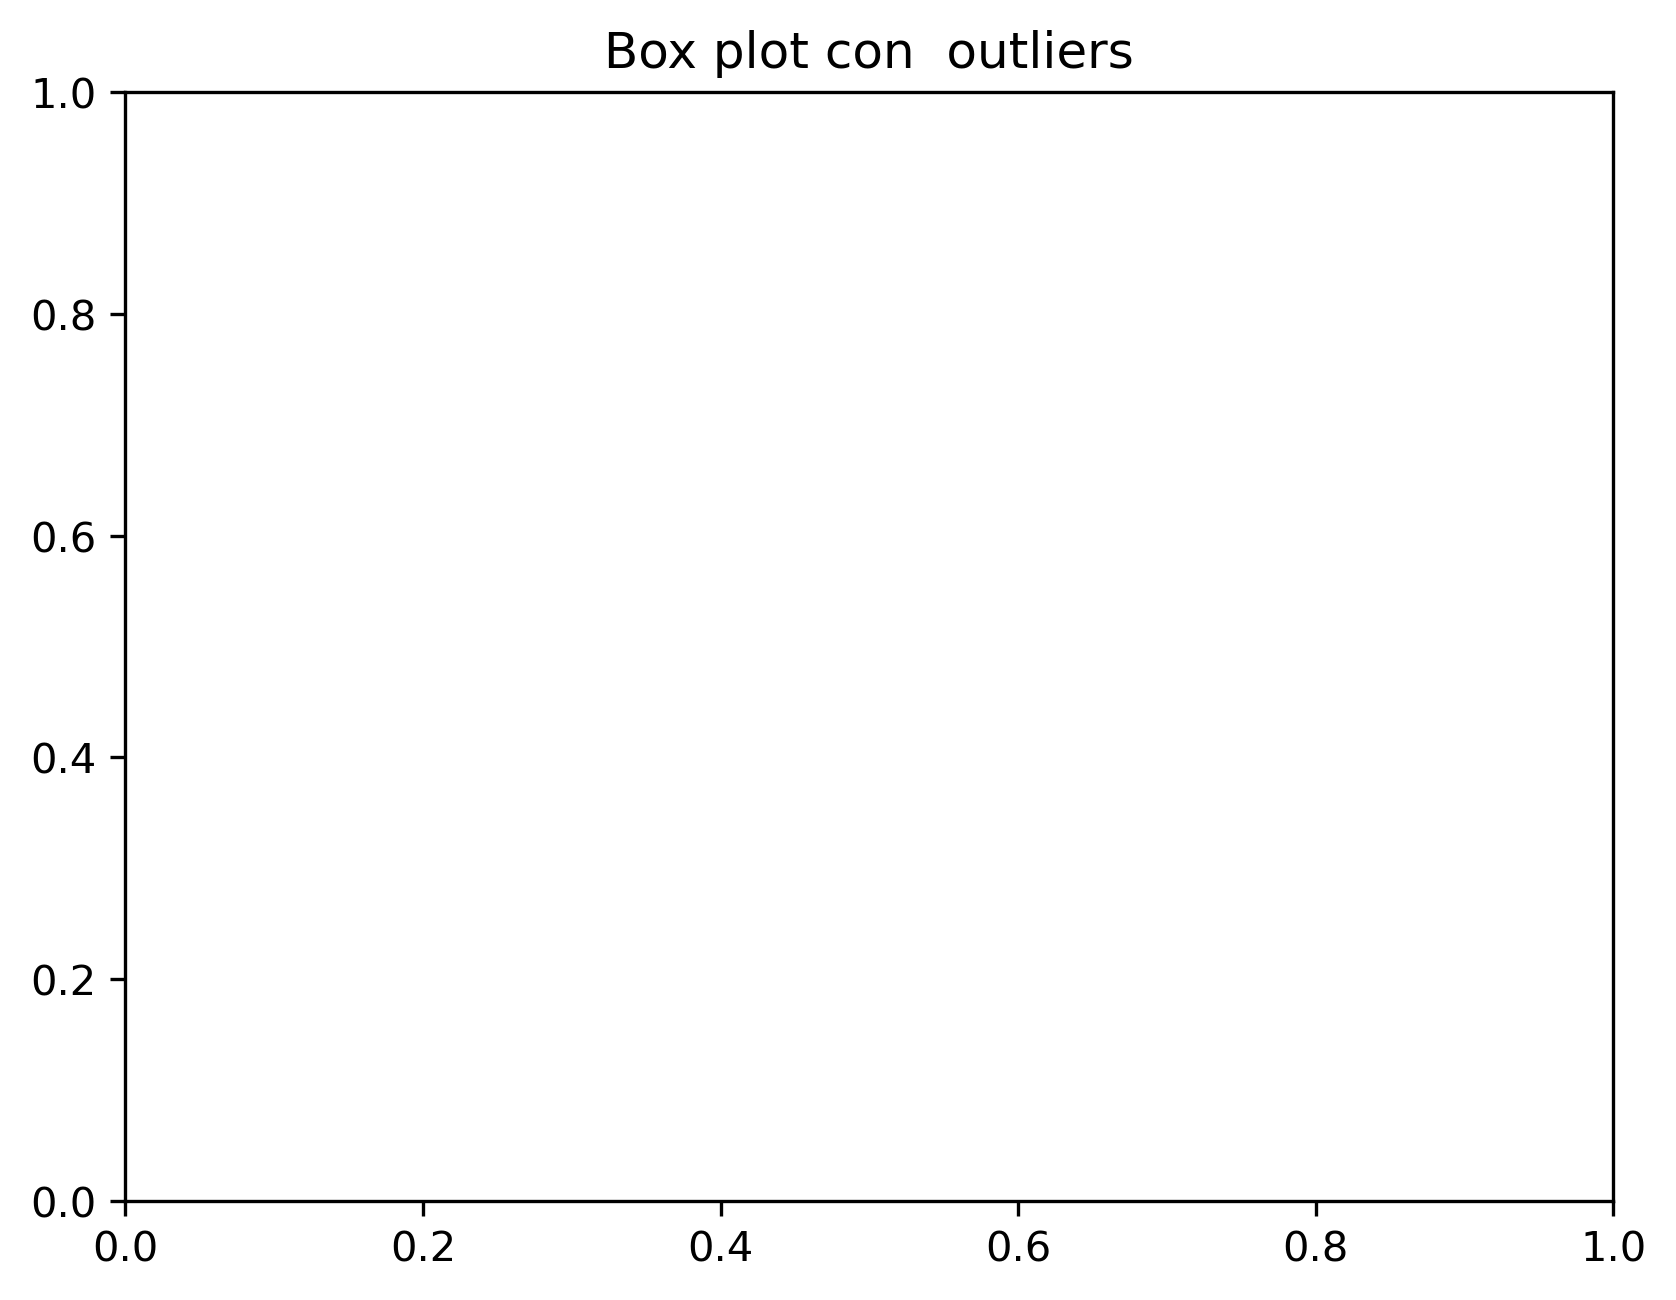

In [69]:
profile_num.boxplot(vert=False, figsize=(12, 8), showfliers=True)
plt.figure(dpi=300)
plt.title('Box plot con  outliers')
plt.show()

## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

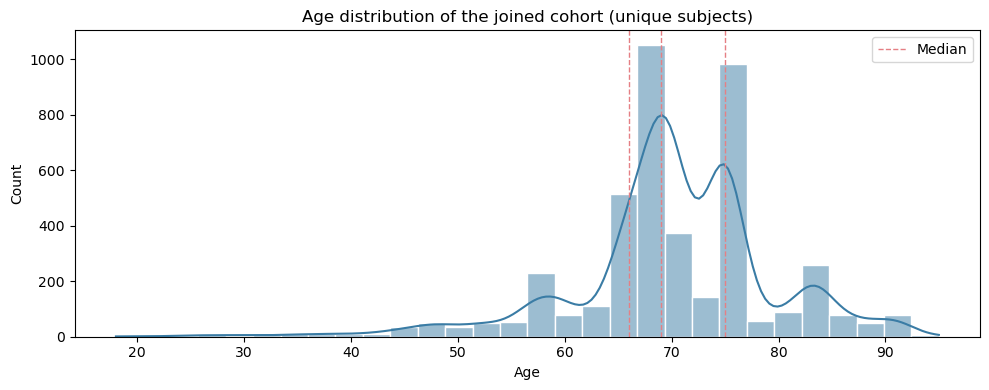

In [70]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)
unique_subject_age = (
    joined_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

## Sex distribution per ICD code

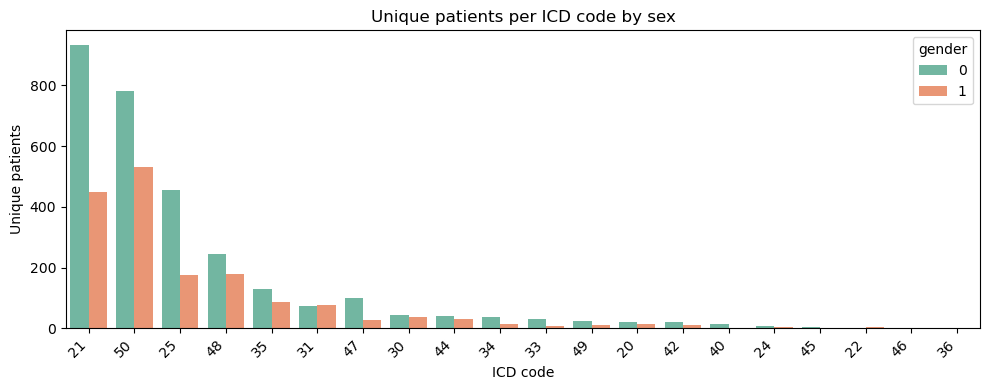

In [71]:
counts = (
    joined_df.groupby(['icd_code_joined', 'gender'])['subject_id']
    .nunique()
    .reset_index(name='unique_patients')
)

icd_order = (
    counts.groupby('icd_code_joined')['unique_patients']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=counts,
    x='icd_code_joined',
    y='unique_patients',
    hue='gender',
    palette='Set2',
    order=icd_order
)
plt.title('Unique patients per ICD code by sex')
plt.xlabel('ICD code')
plt.ylabel('Unique patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

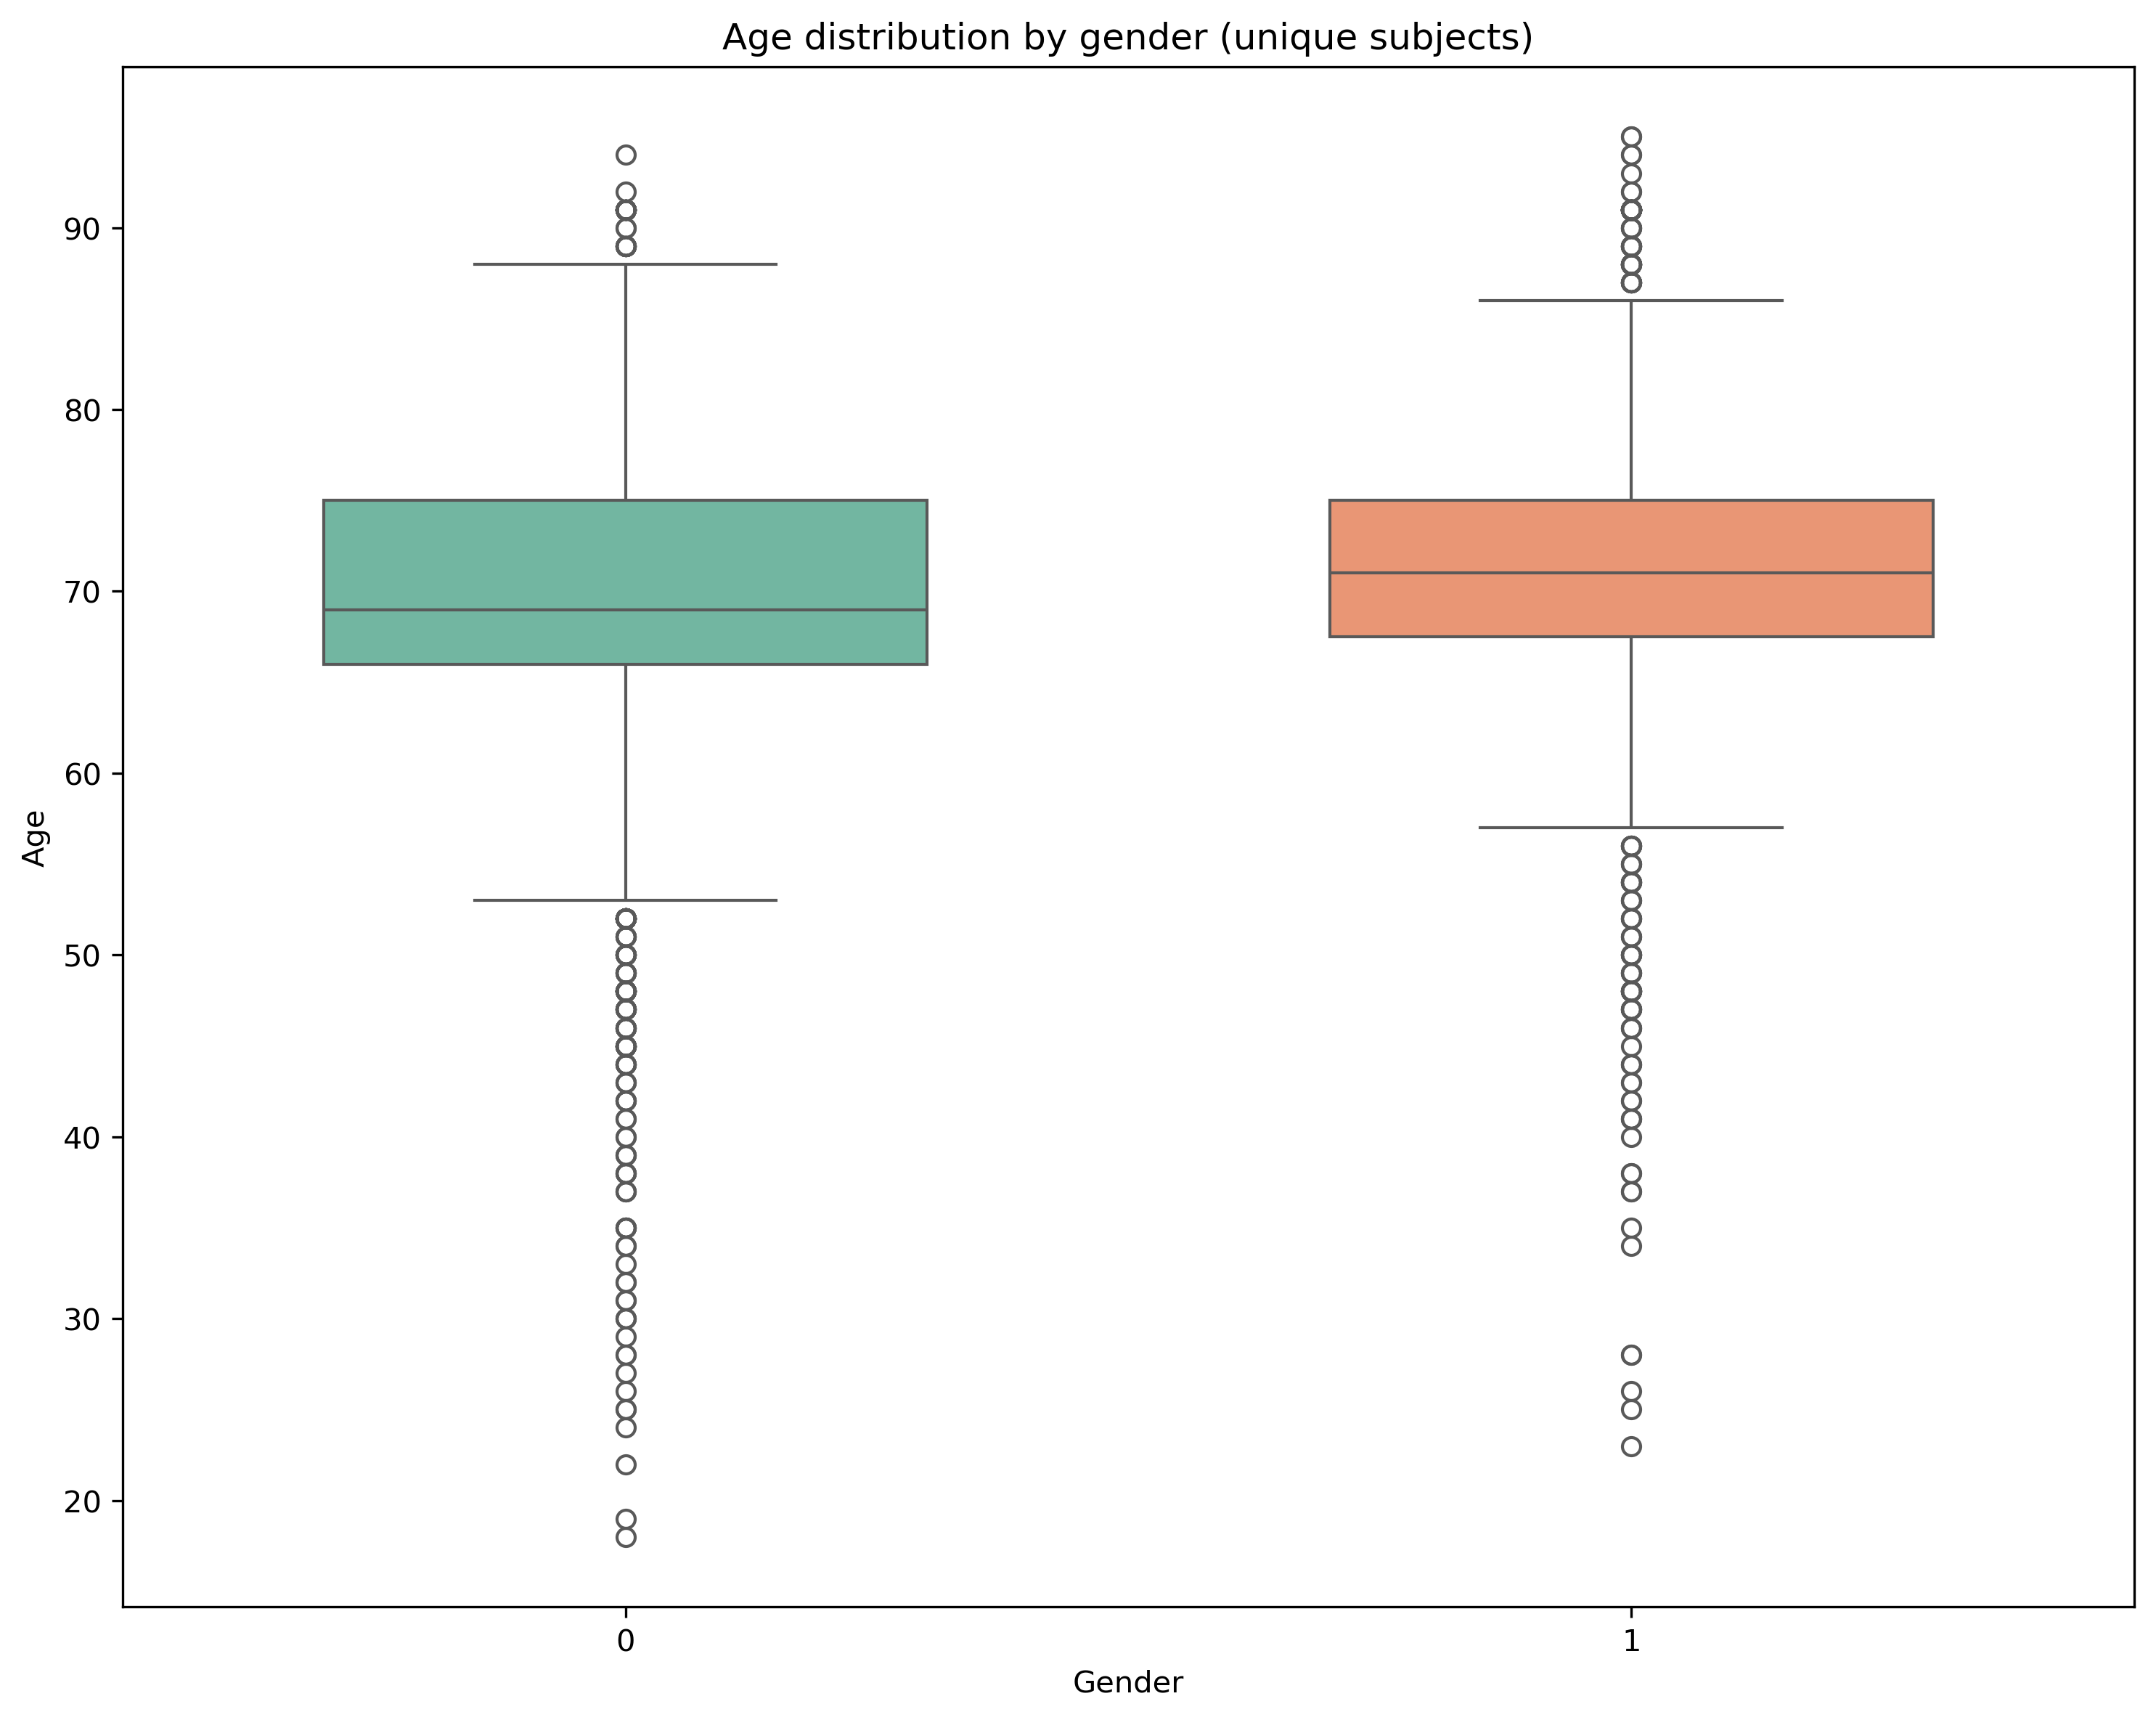

In [72]:
subject_age = (
    joined_df[['subject_id', 'gender', 'age']]
    .dropna(subset=['gender', 'age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=subject_age,
    x='gender',
    y='age',
    hue='gender',
    palette='Set2',
    width=0.6,
    dodge=False,
    legend=False
)
plt.title('Age distribution by gender (unique subjects)')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()

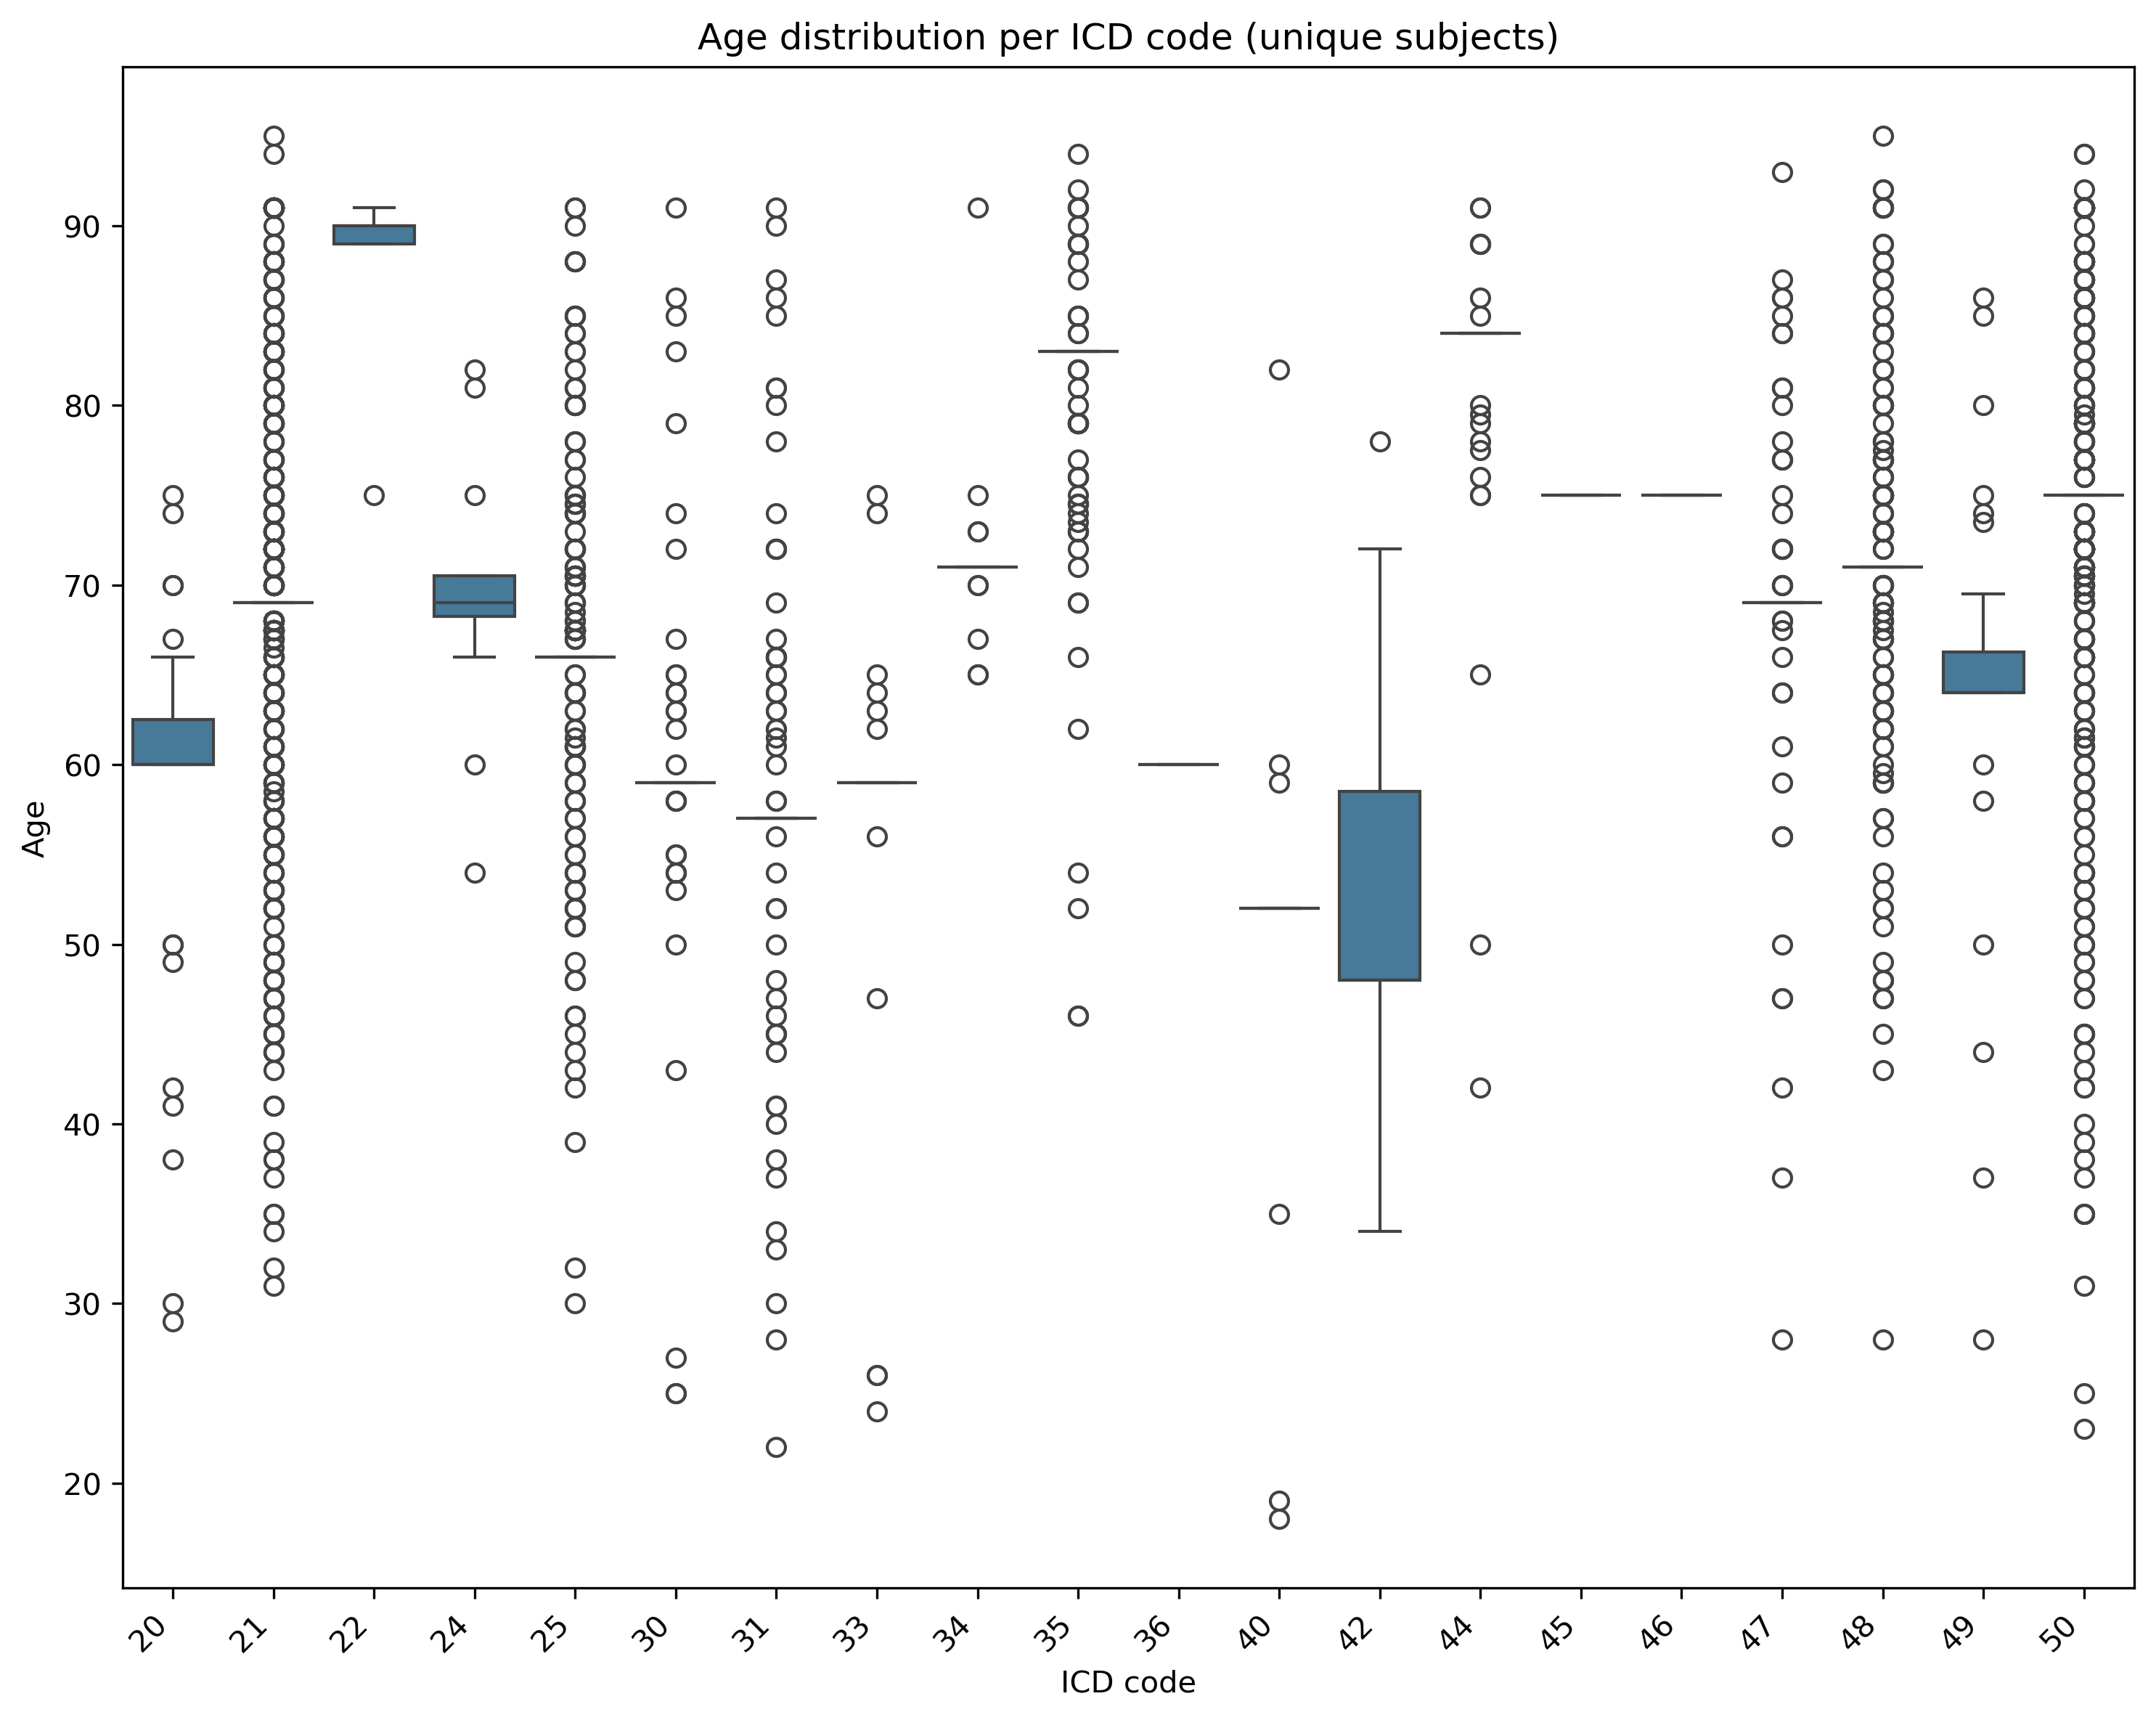

In [73]:
#to visualize for each icd_code the age of the patient 
icd_age = (
    joined_df[['subject_id', 'icd_code_joined', 'age']]
    .dropna(subset=['icd_code_joined', 'age'])
    .drop_duplicates(subset=['subject_id', 'icd_code_joined'])
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    color='#3A7CA5'
)
plt.title('Age distribution per ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

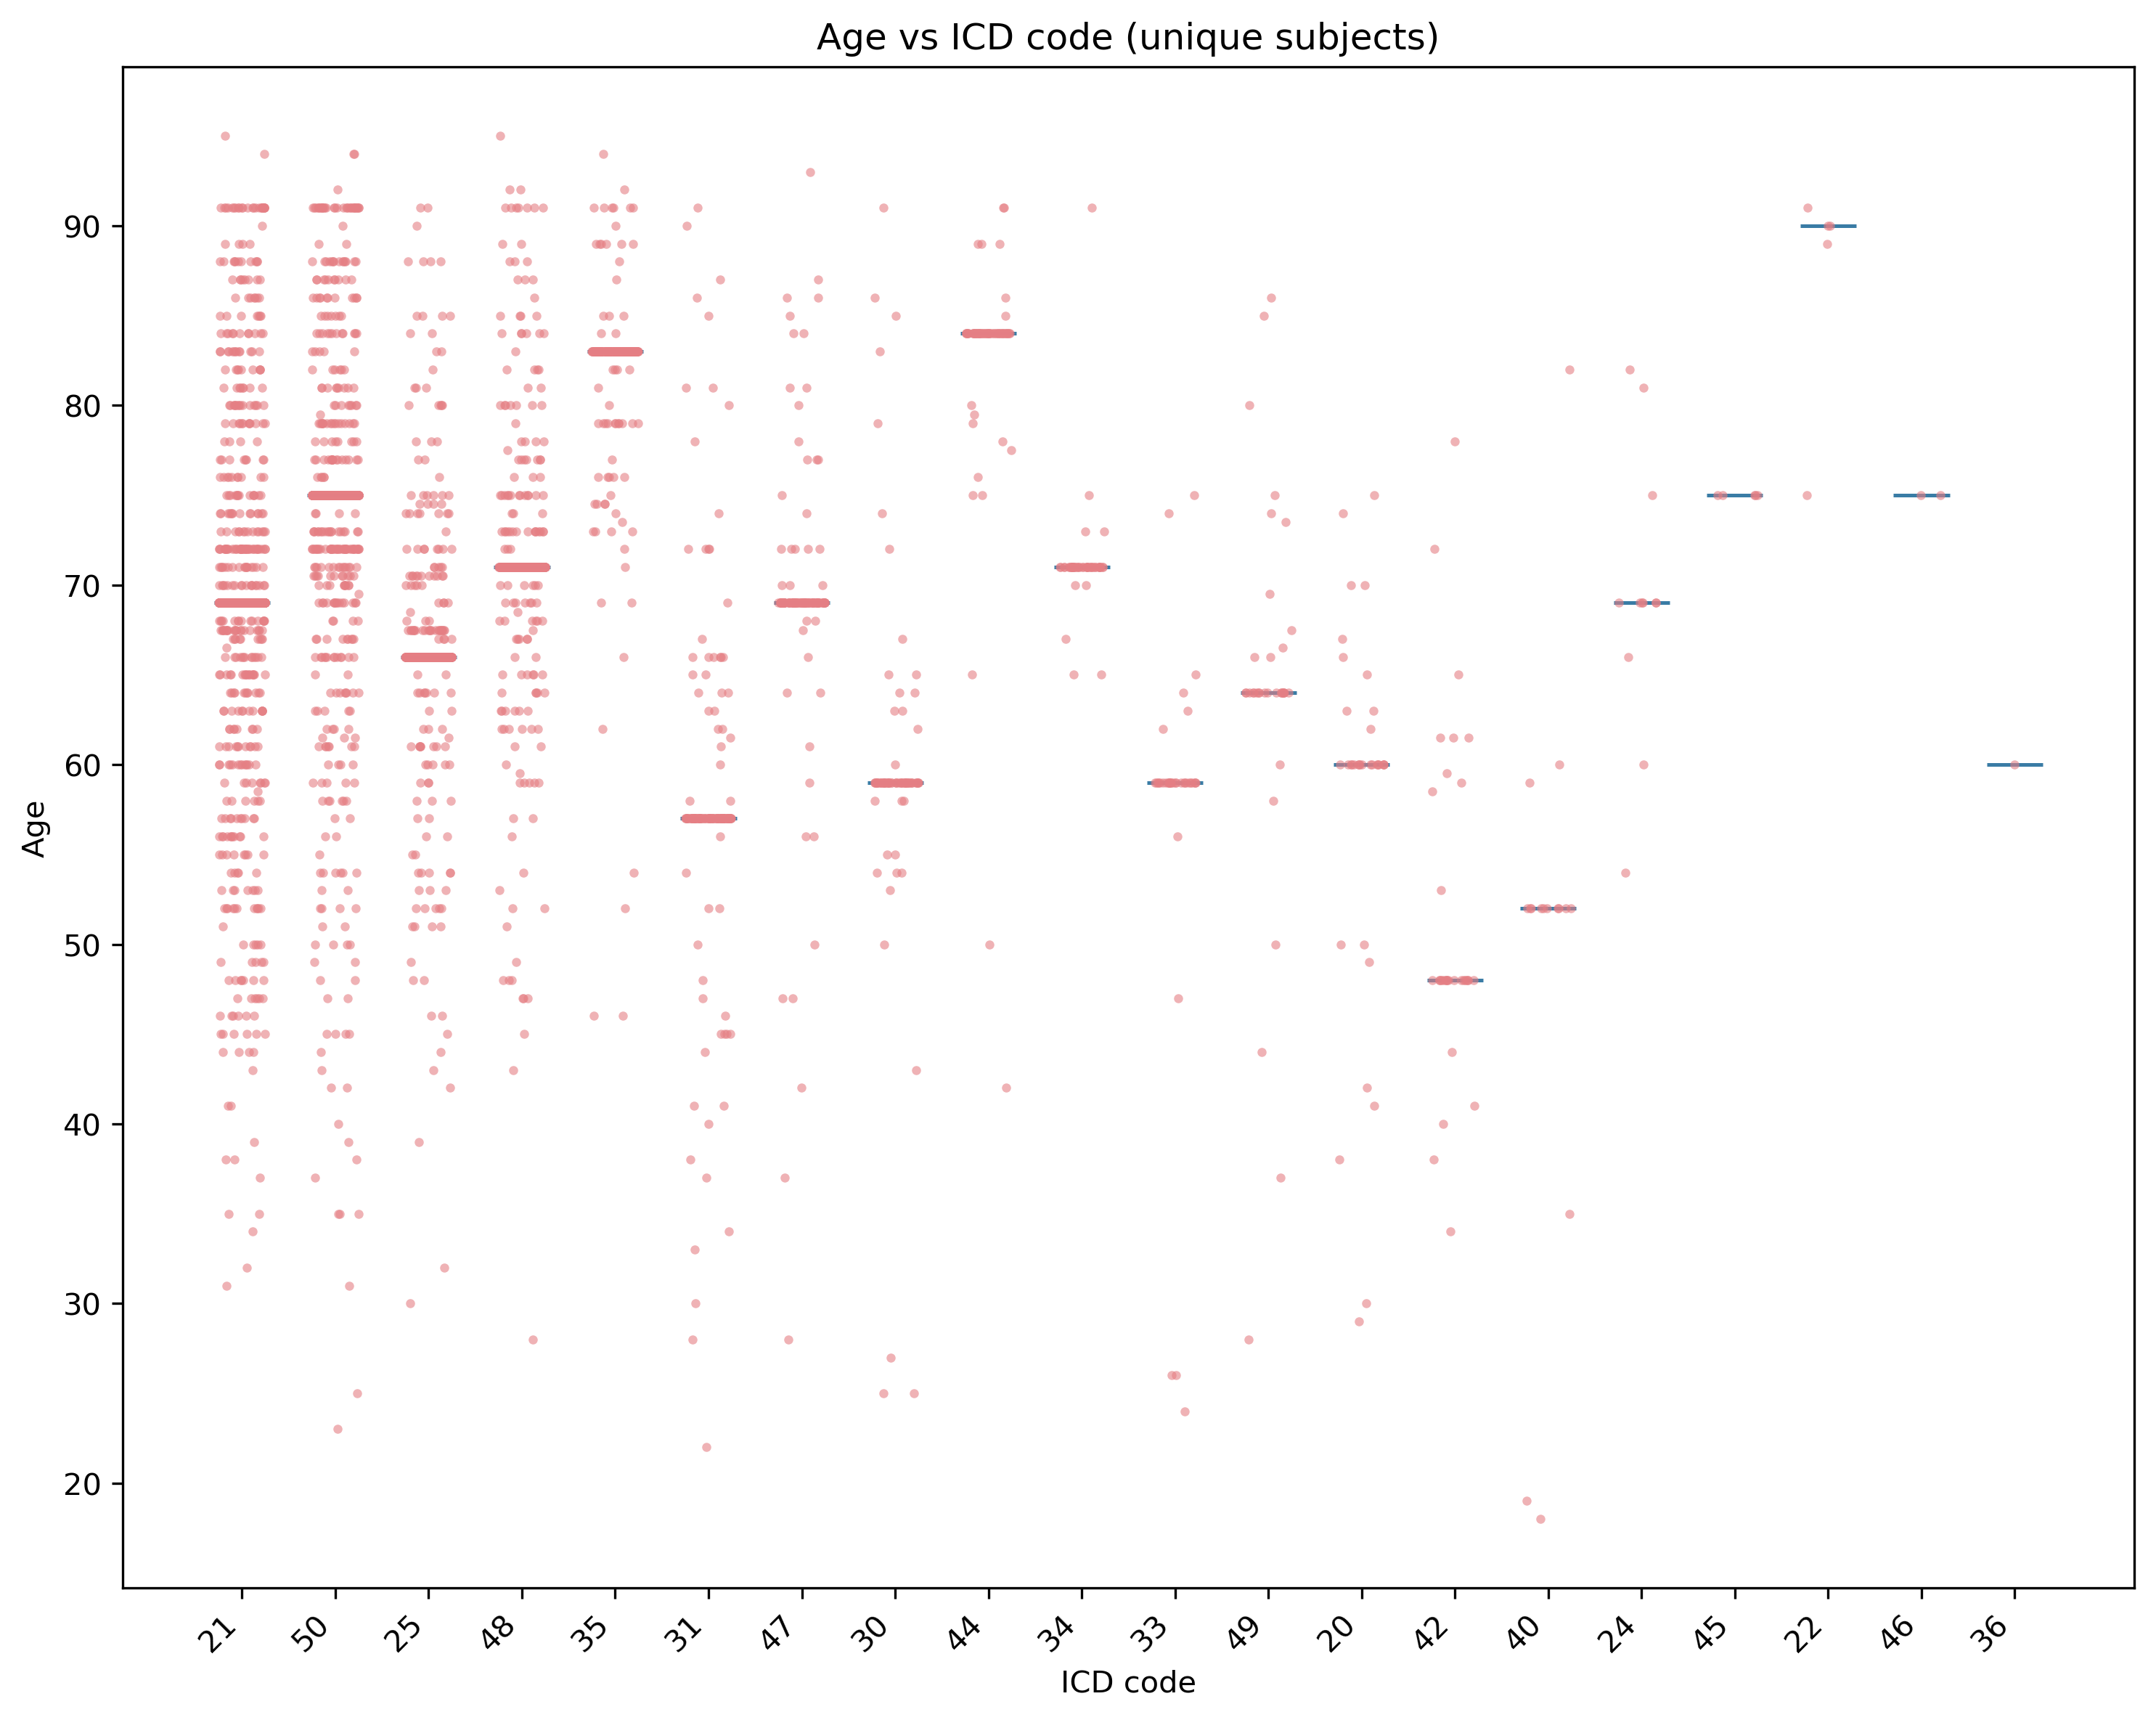

In [74]:
icd_order = (
    icd_age.groupby('icd_code_joined')['subject_id']
    .nunique()
    .sort_values(ascending=False)
    .index
)

median_age_by_icd = (
    icd_age.groupby('icd_code_joined')['age']
    .median()
    .reindex(icd_order)
)

plt.figure(figsize=(10, 8), dpi=300)
sns.stripplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    order=icd_order,
    color='#E57F84',
    jitter=0.25,
    size=3,
    alpha=0.6
)

for idx, age in enumerate(median_age_by_icd):
    plt.hlines(age, idx - 0.3, idx + 0.3, color='#3A7CA5', linewidth=1.2)

plt.title('Age vs ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

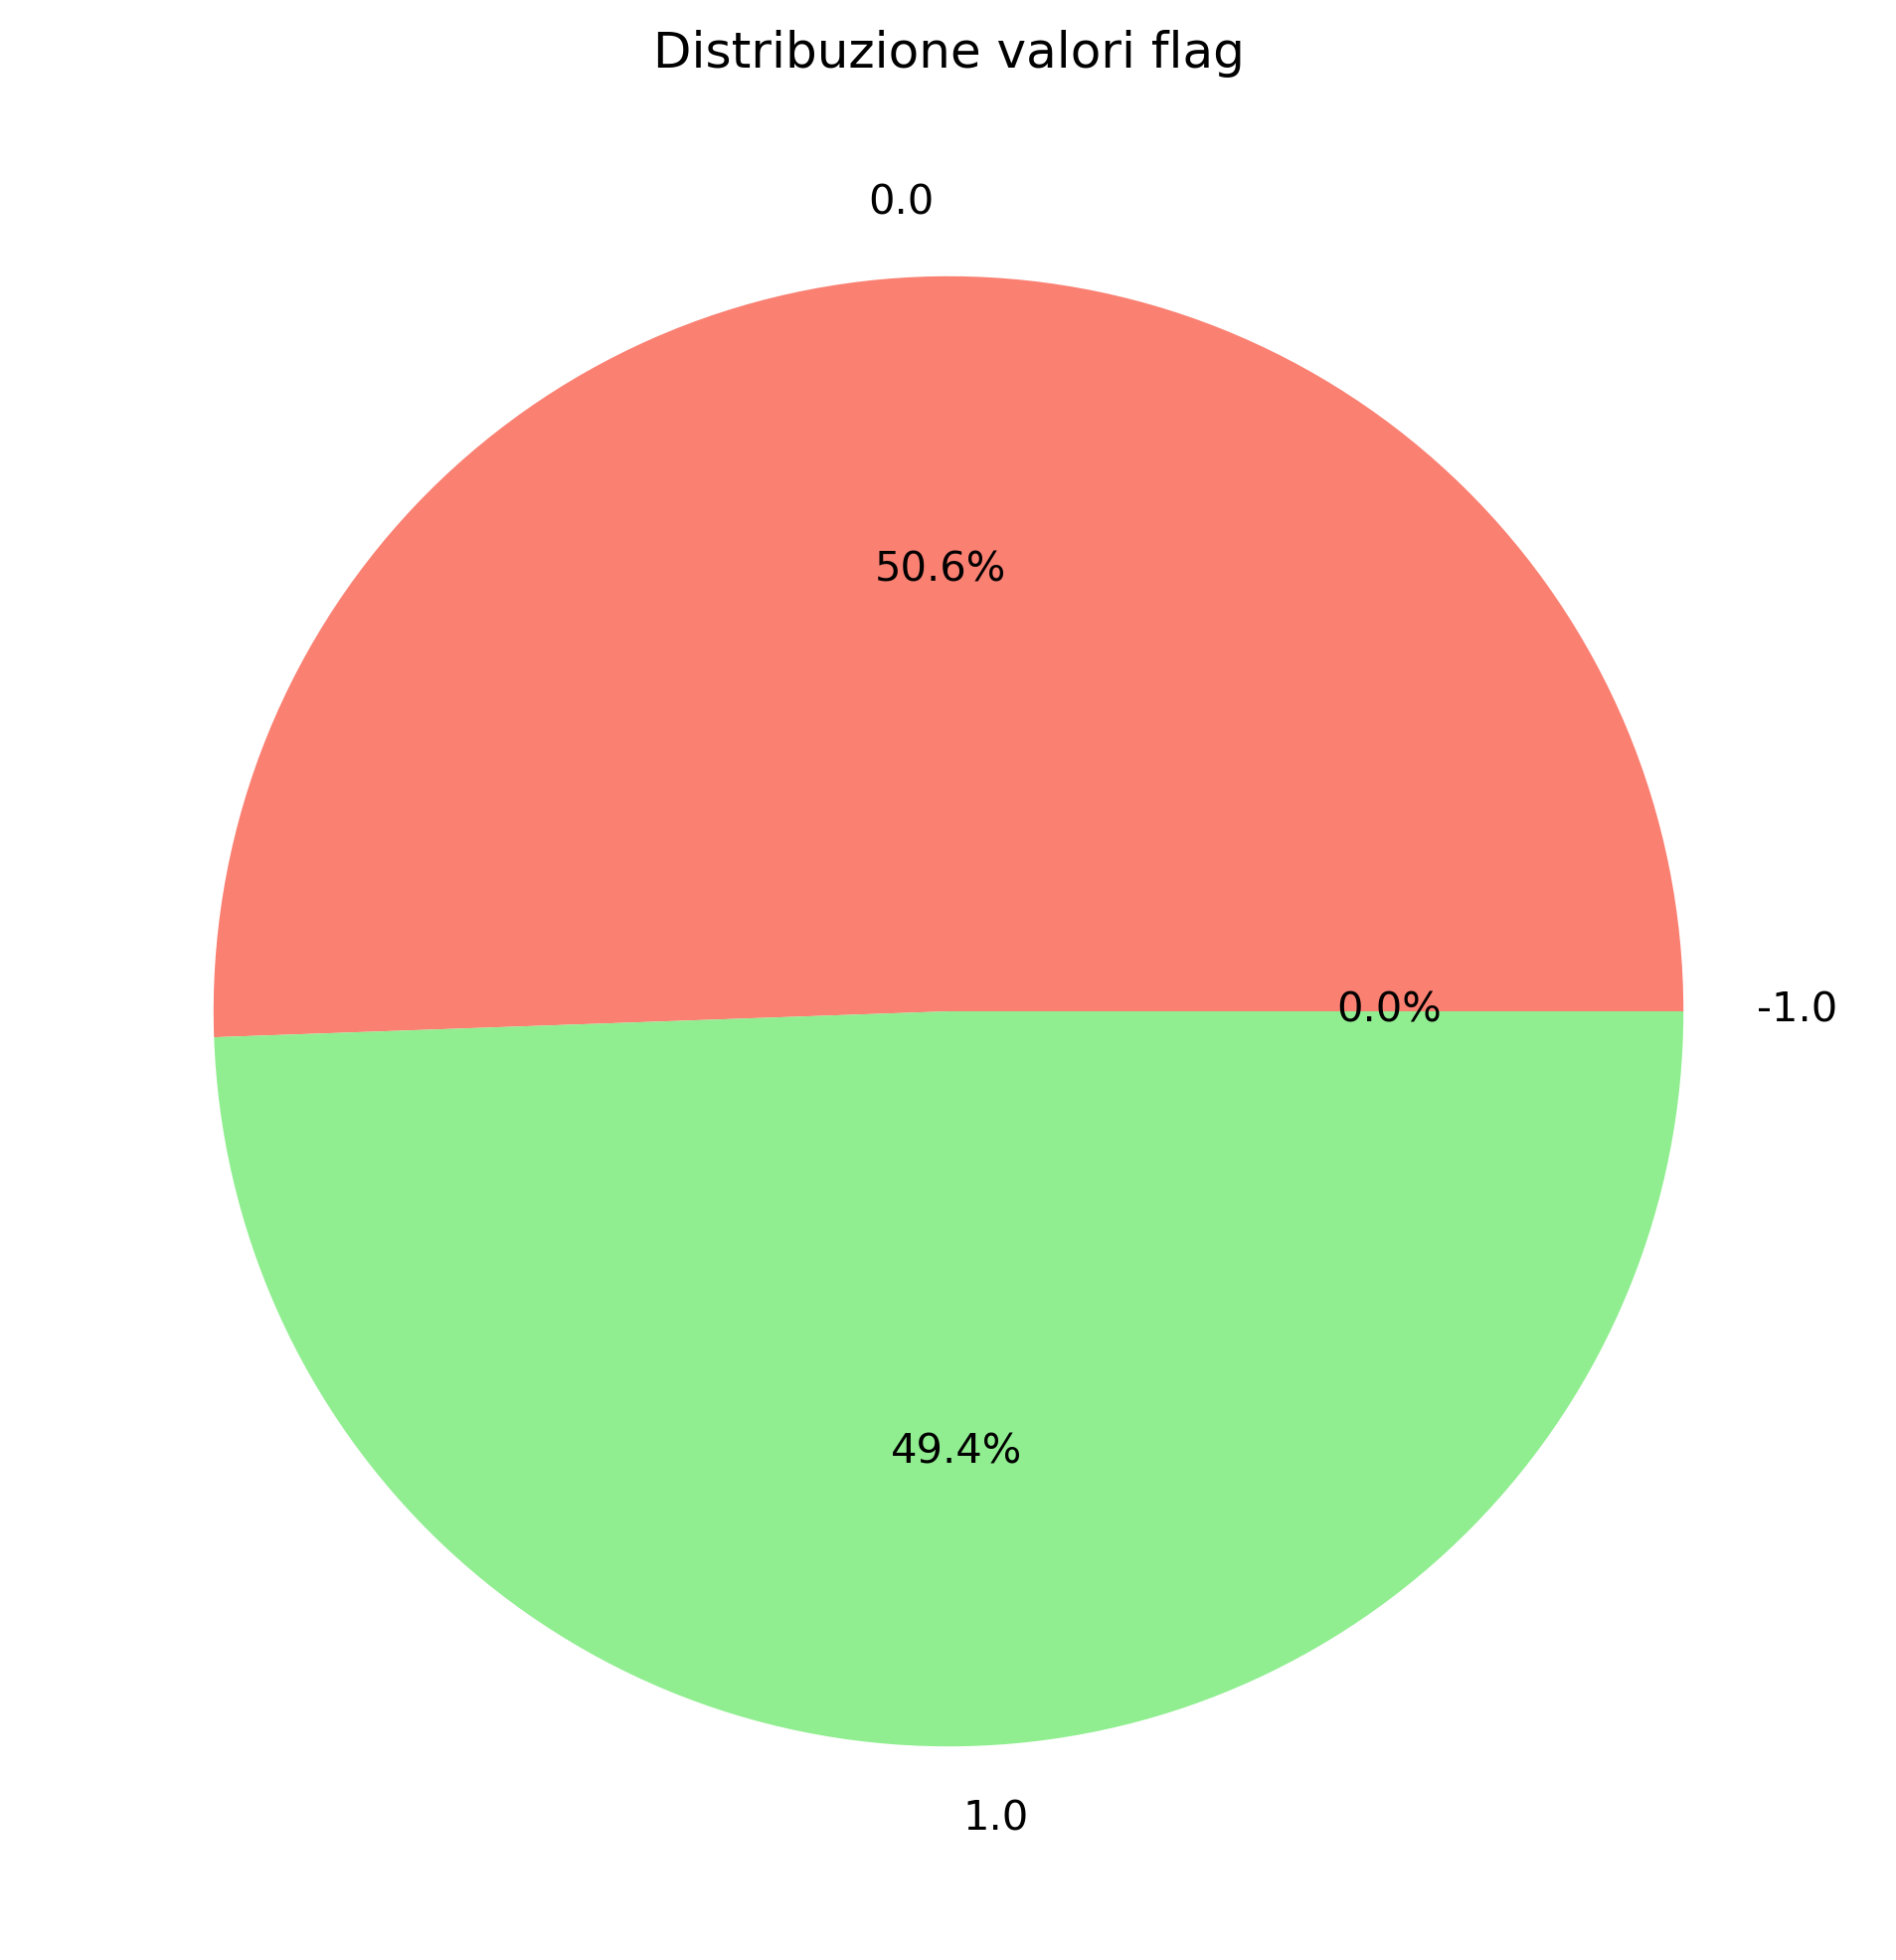

In [75]:
# Prima conta i valori della colonna flag
counts = joined_df['flag'].value_counts().sort_index()

# Poi crea il grafico a torta
plt.figure(figsize=(10, 8), dpi=300)
plt.pie(counts.values, 
        labels=counts.index,  # oppure ['Normale', 'Anormale']
        autopct='%1.1f%%',
        colors=['lightgreen', 'salmon'])
plt.title('Distribuzione valori flag')
plt.show()

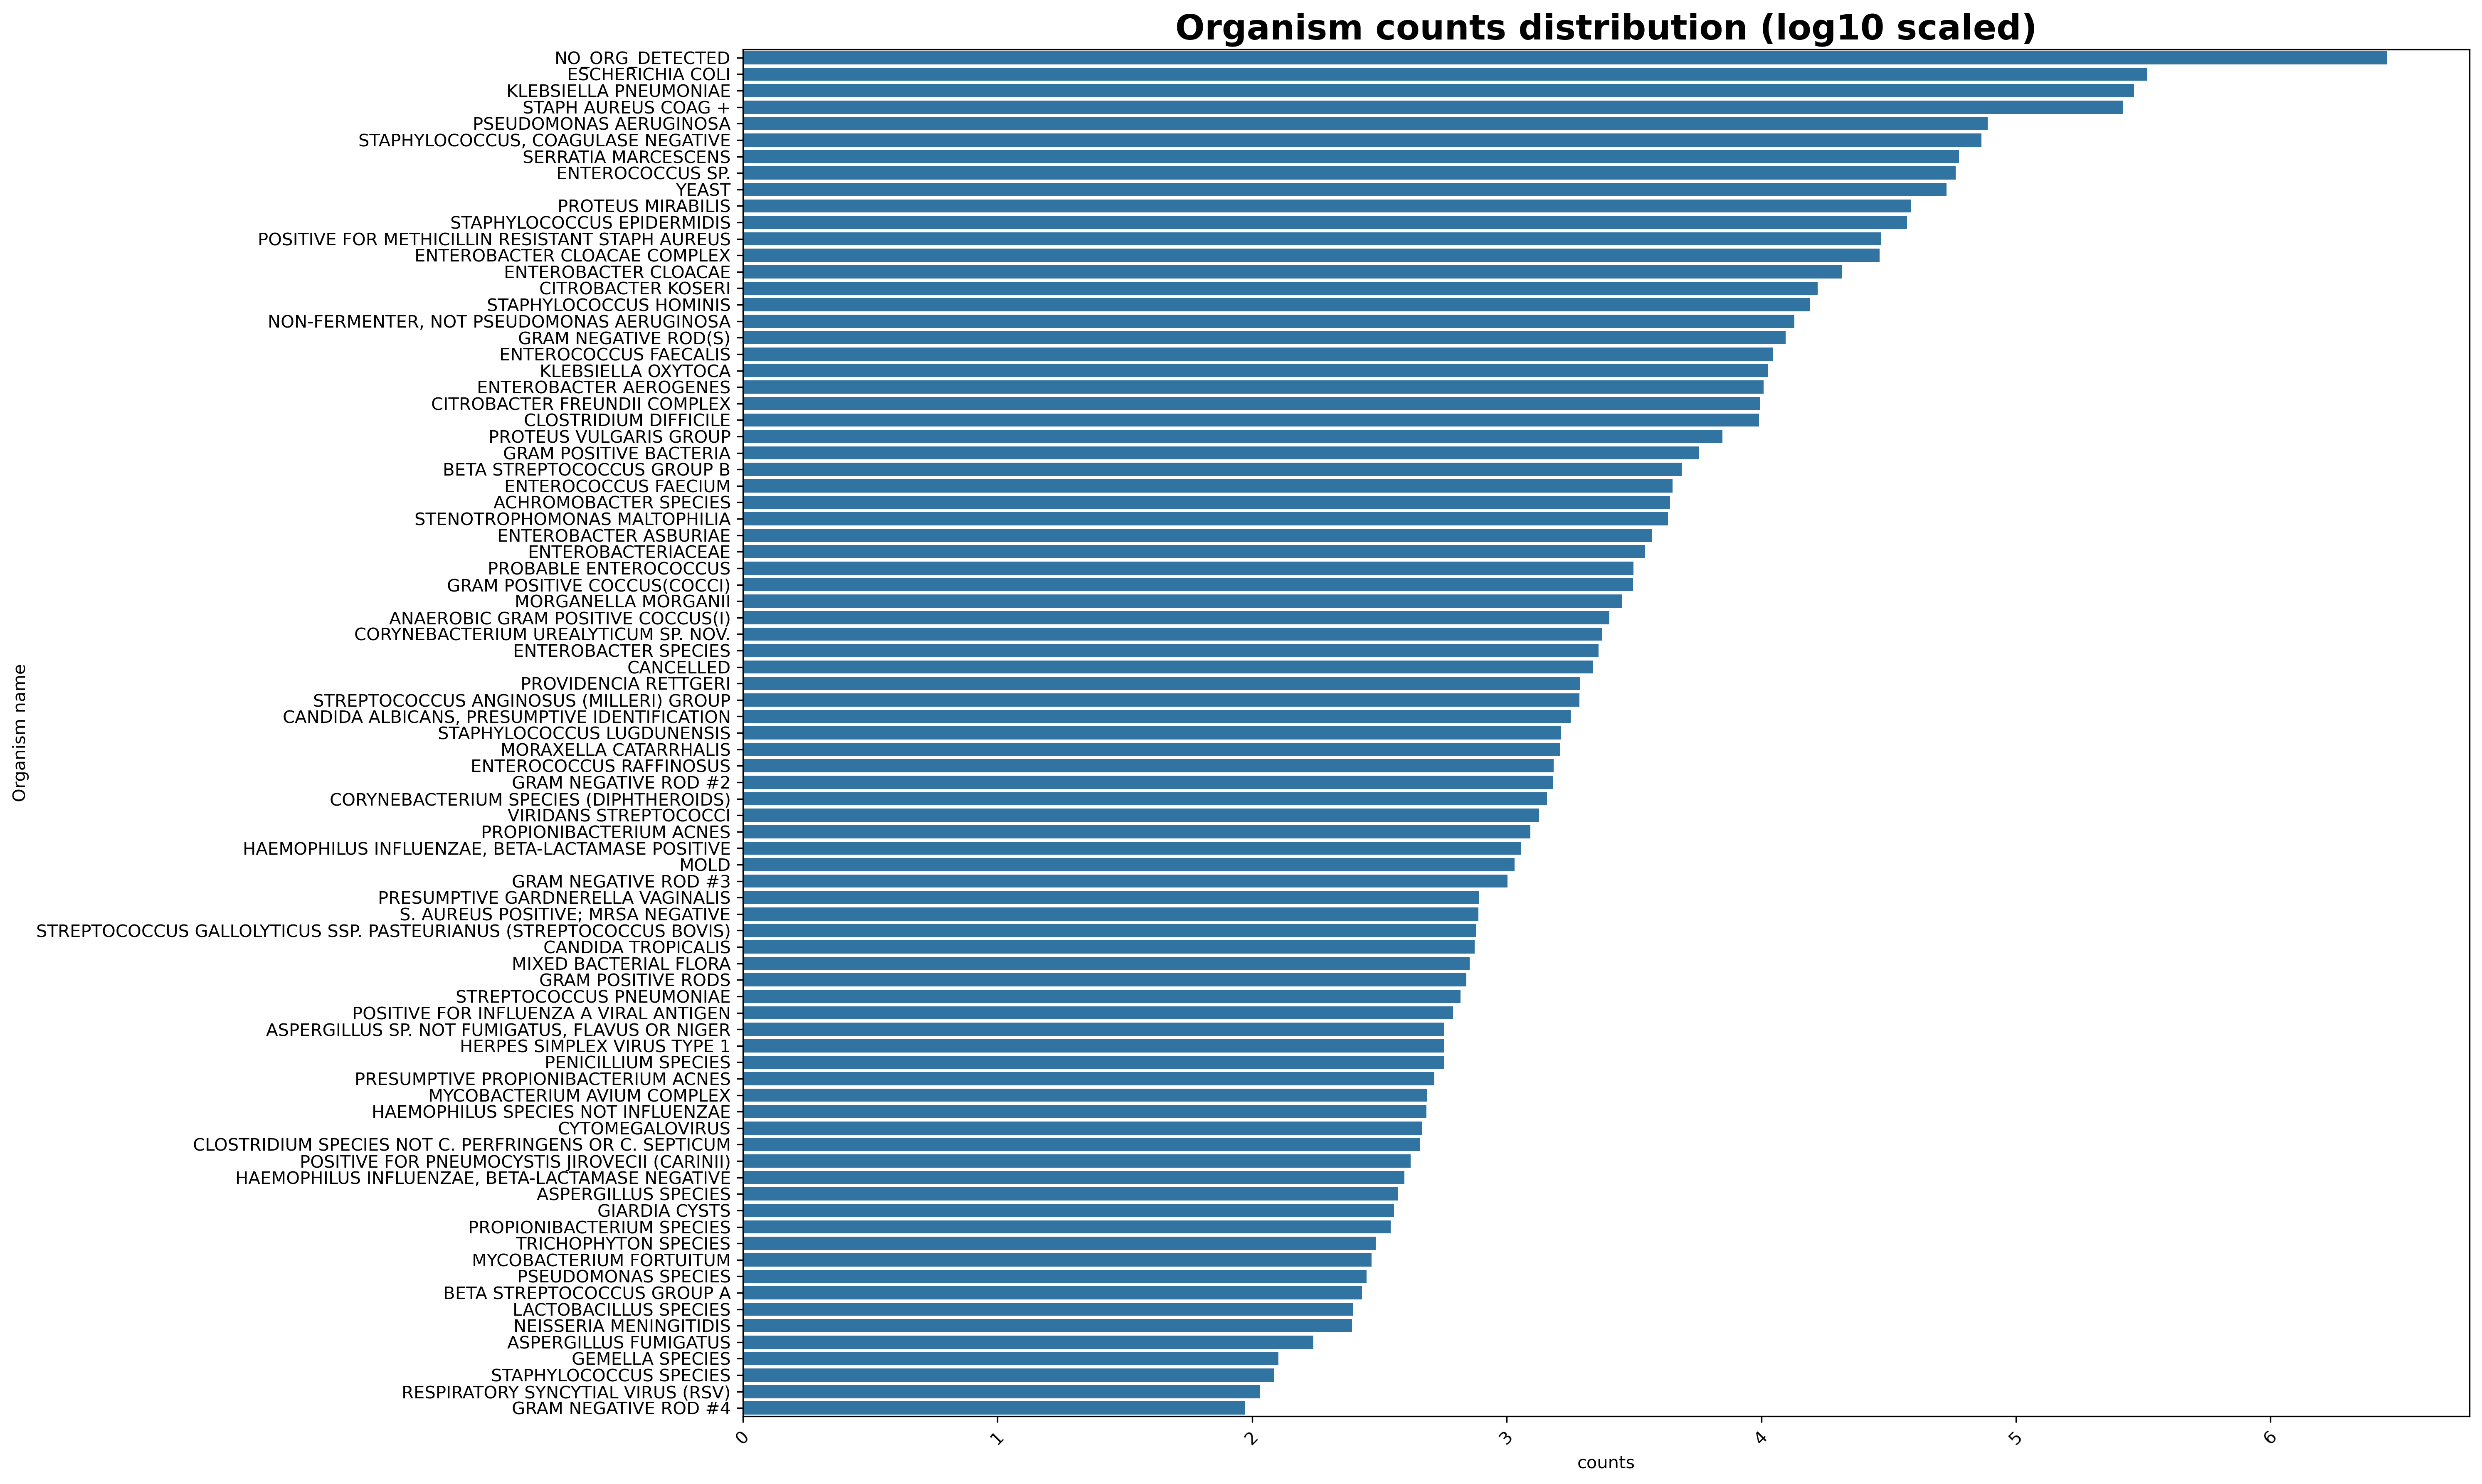

In [76]:
org_count = np.log10(joined_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

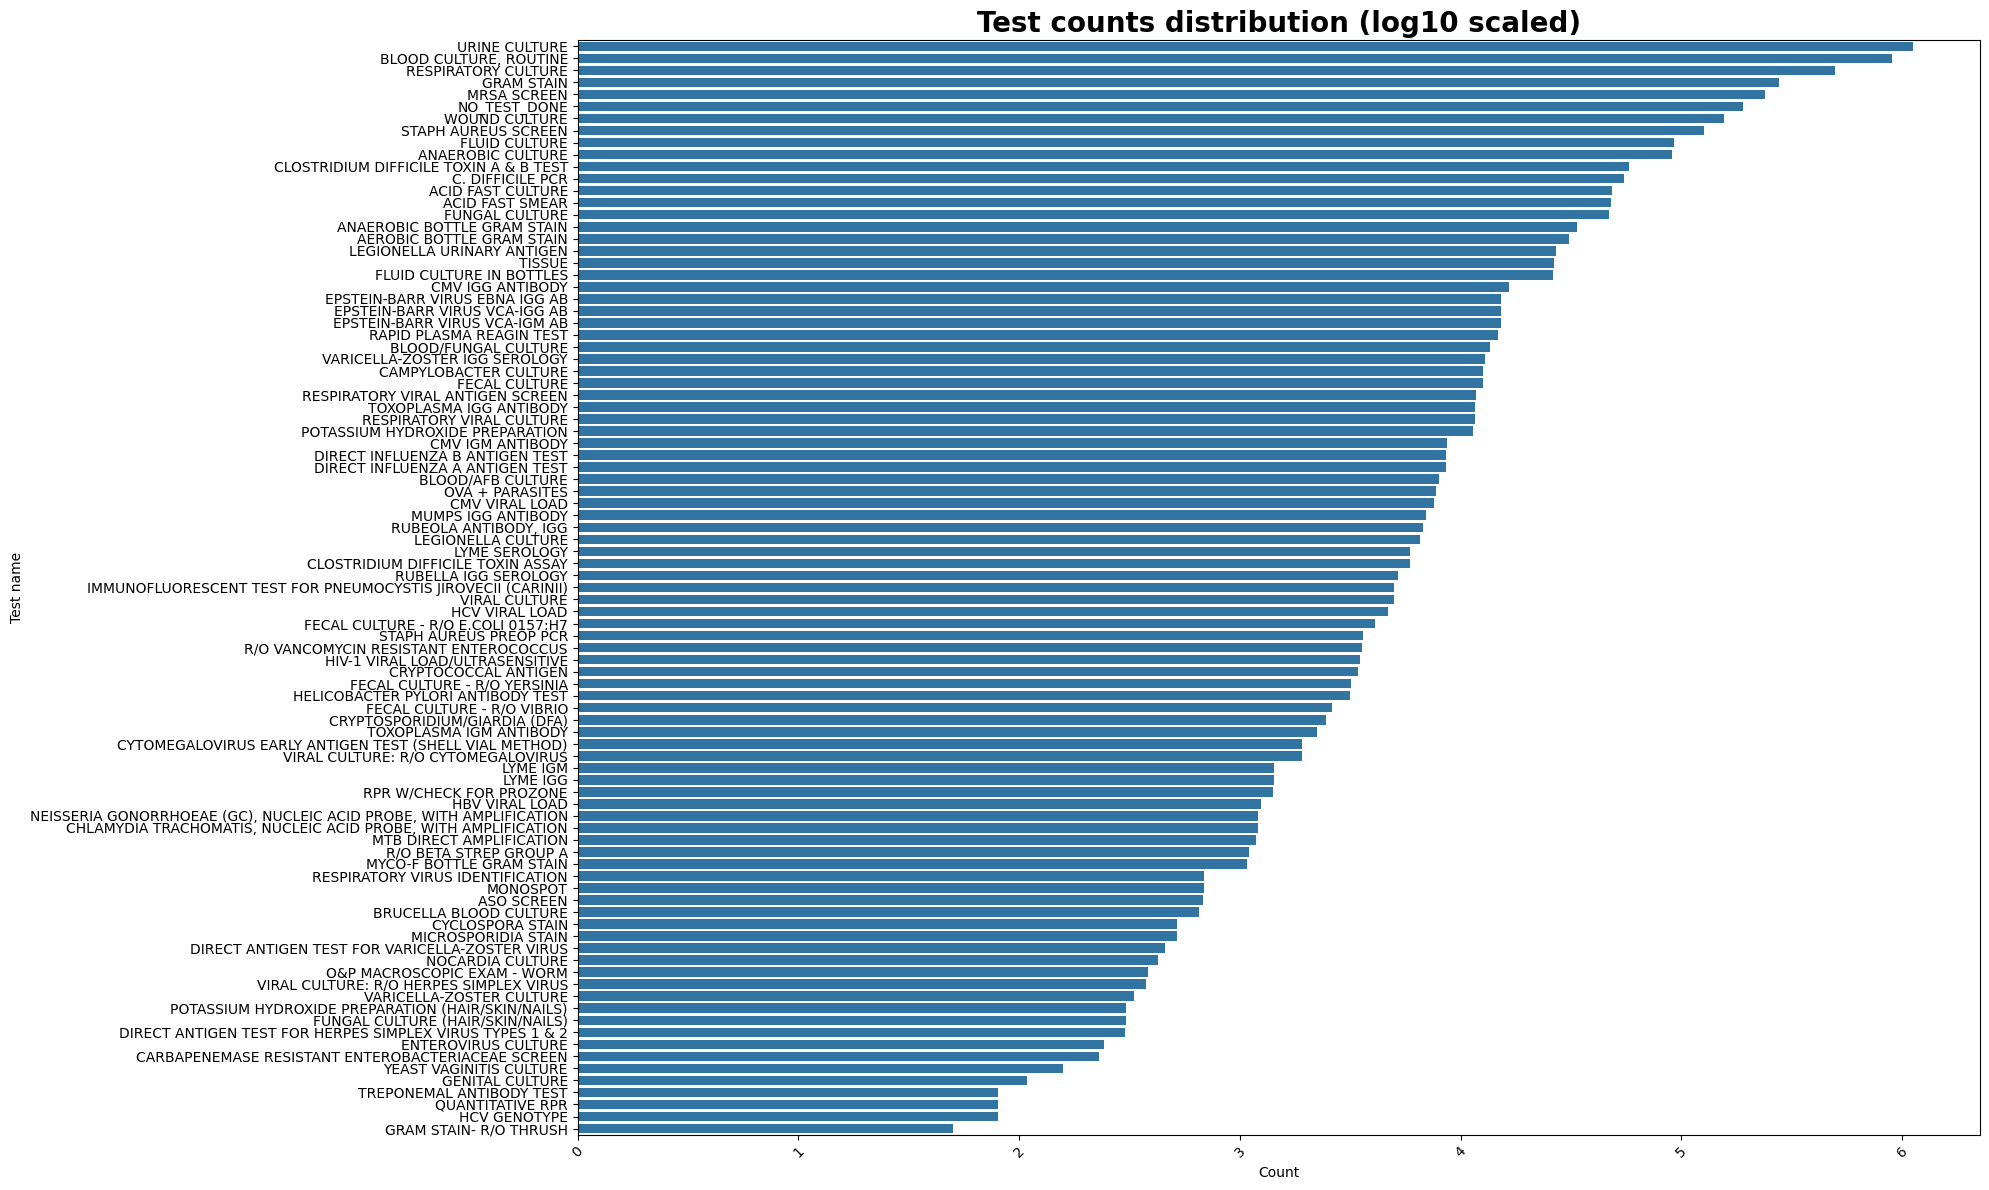

In [77]:
test_count = np.log10(joined_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

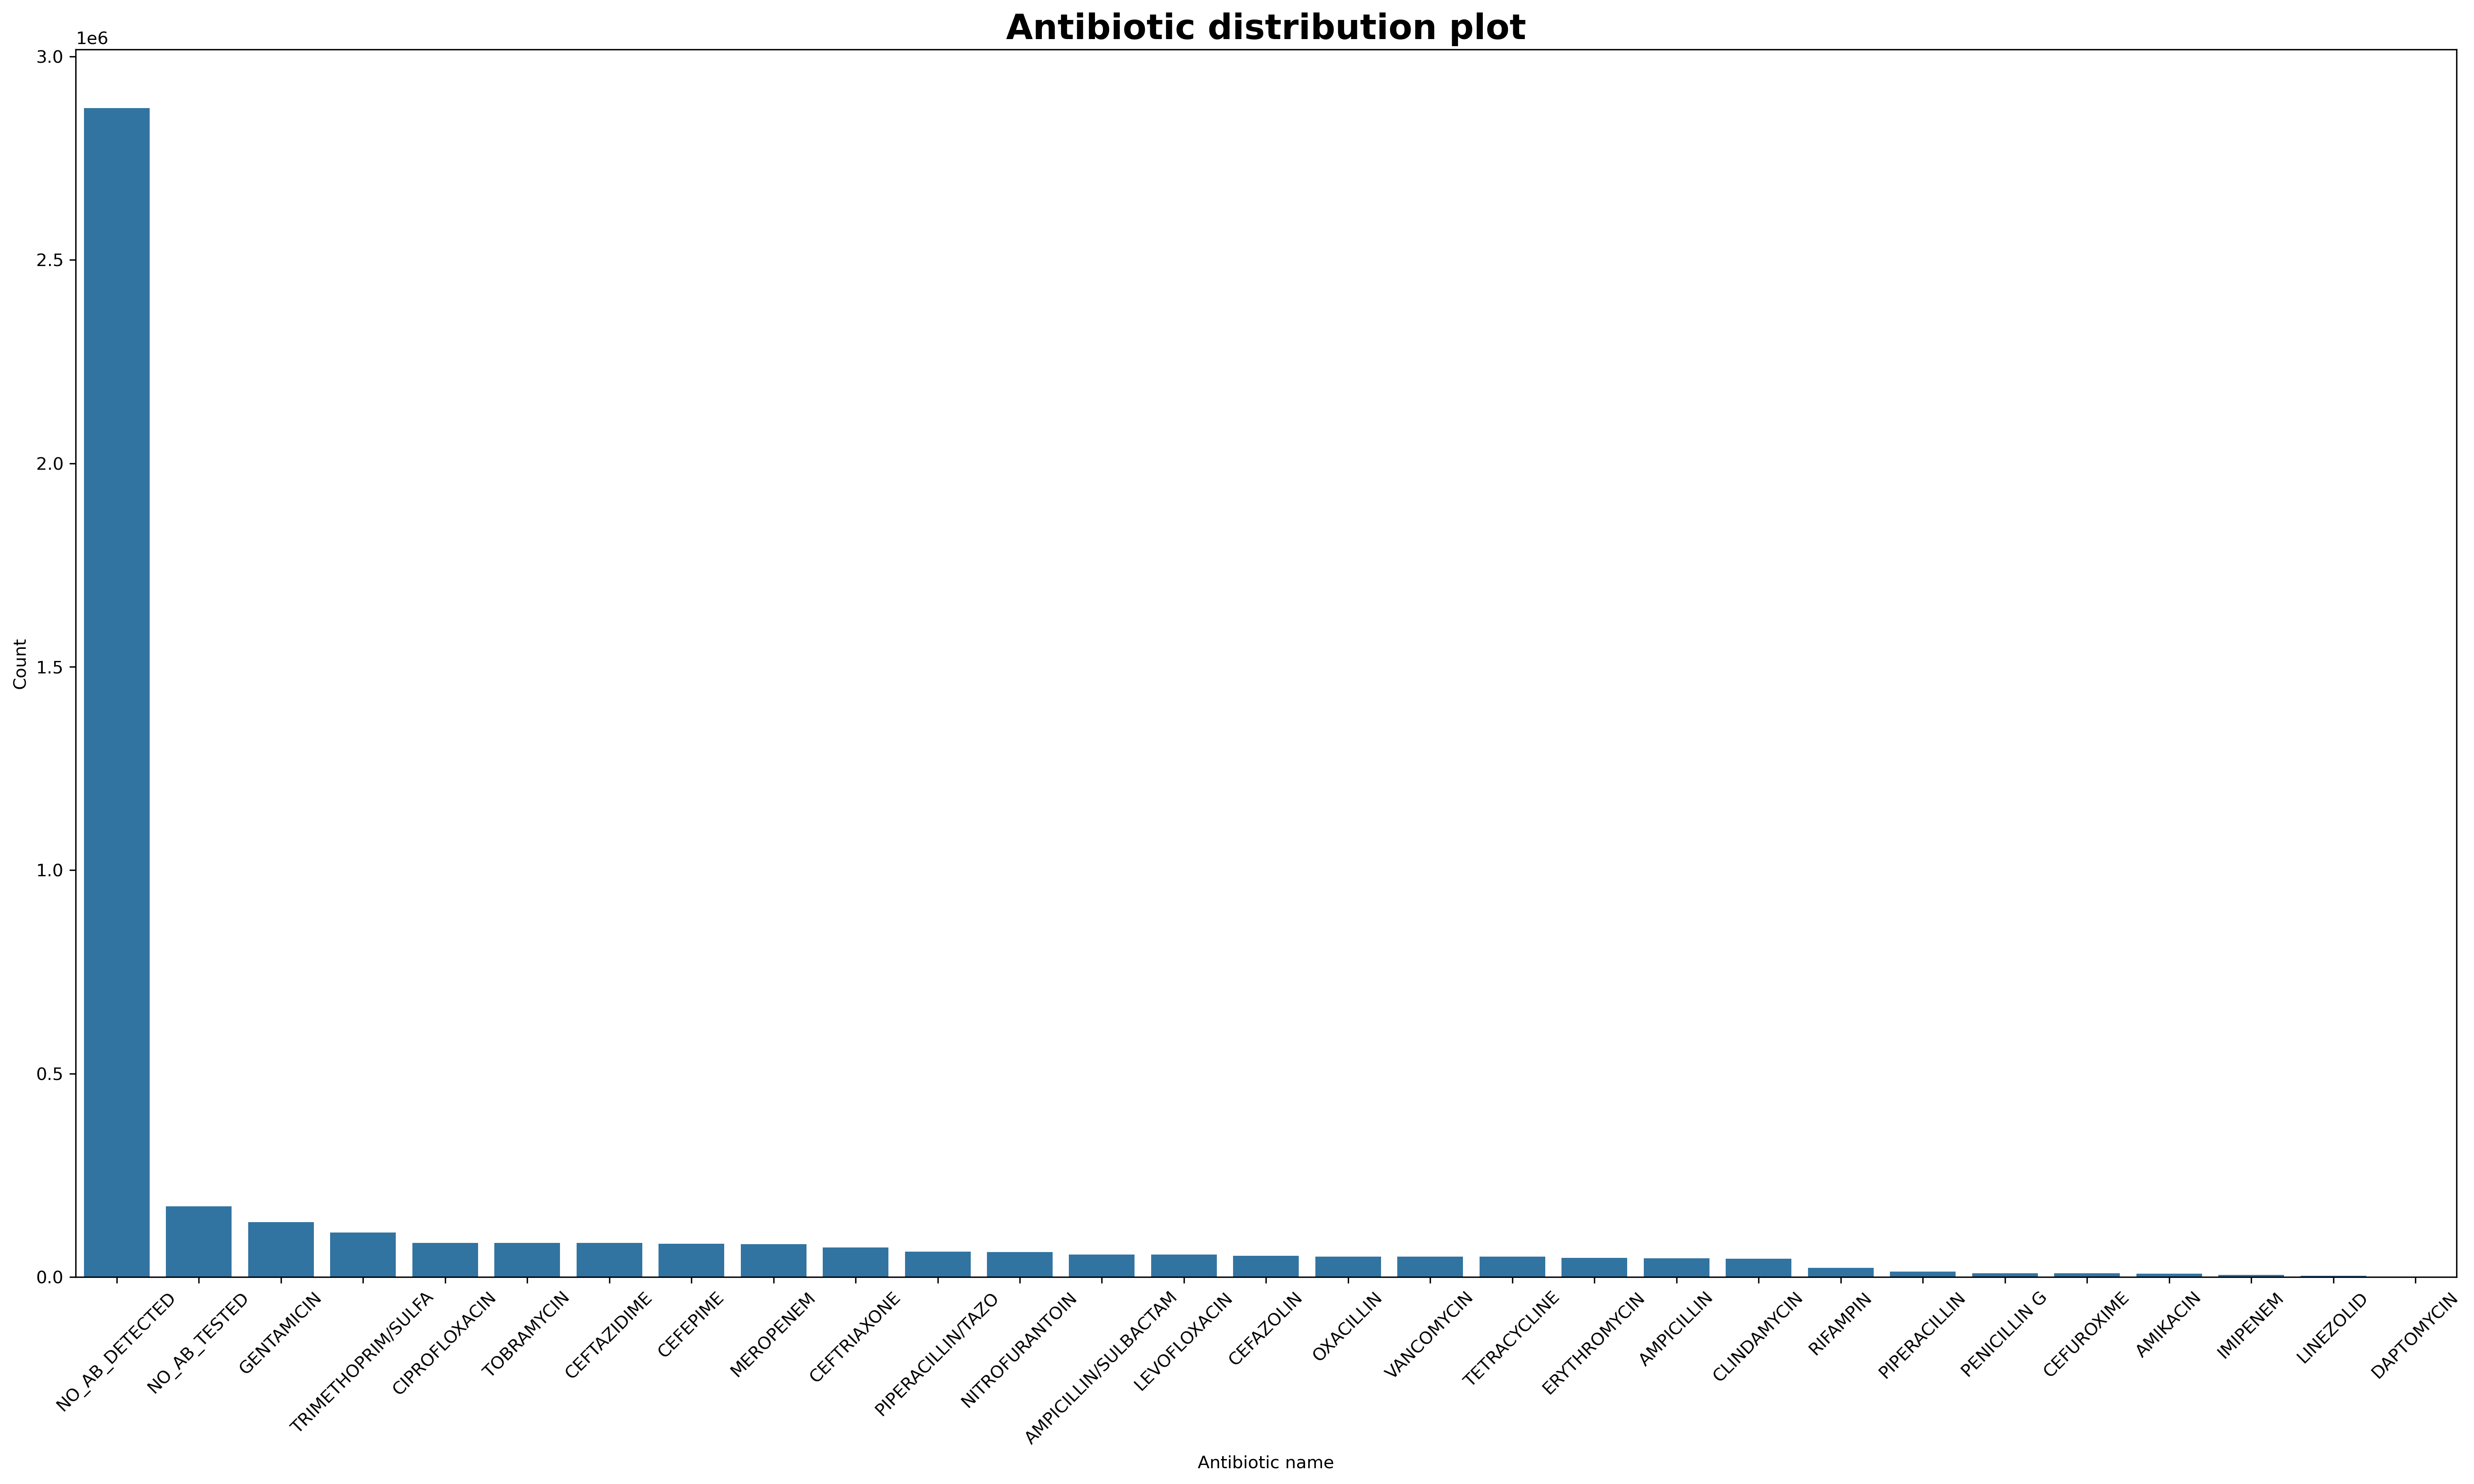

In [78]:
ab_count =joined_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

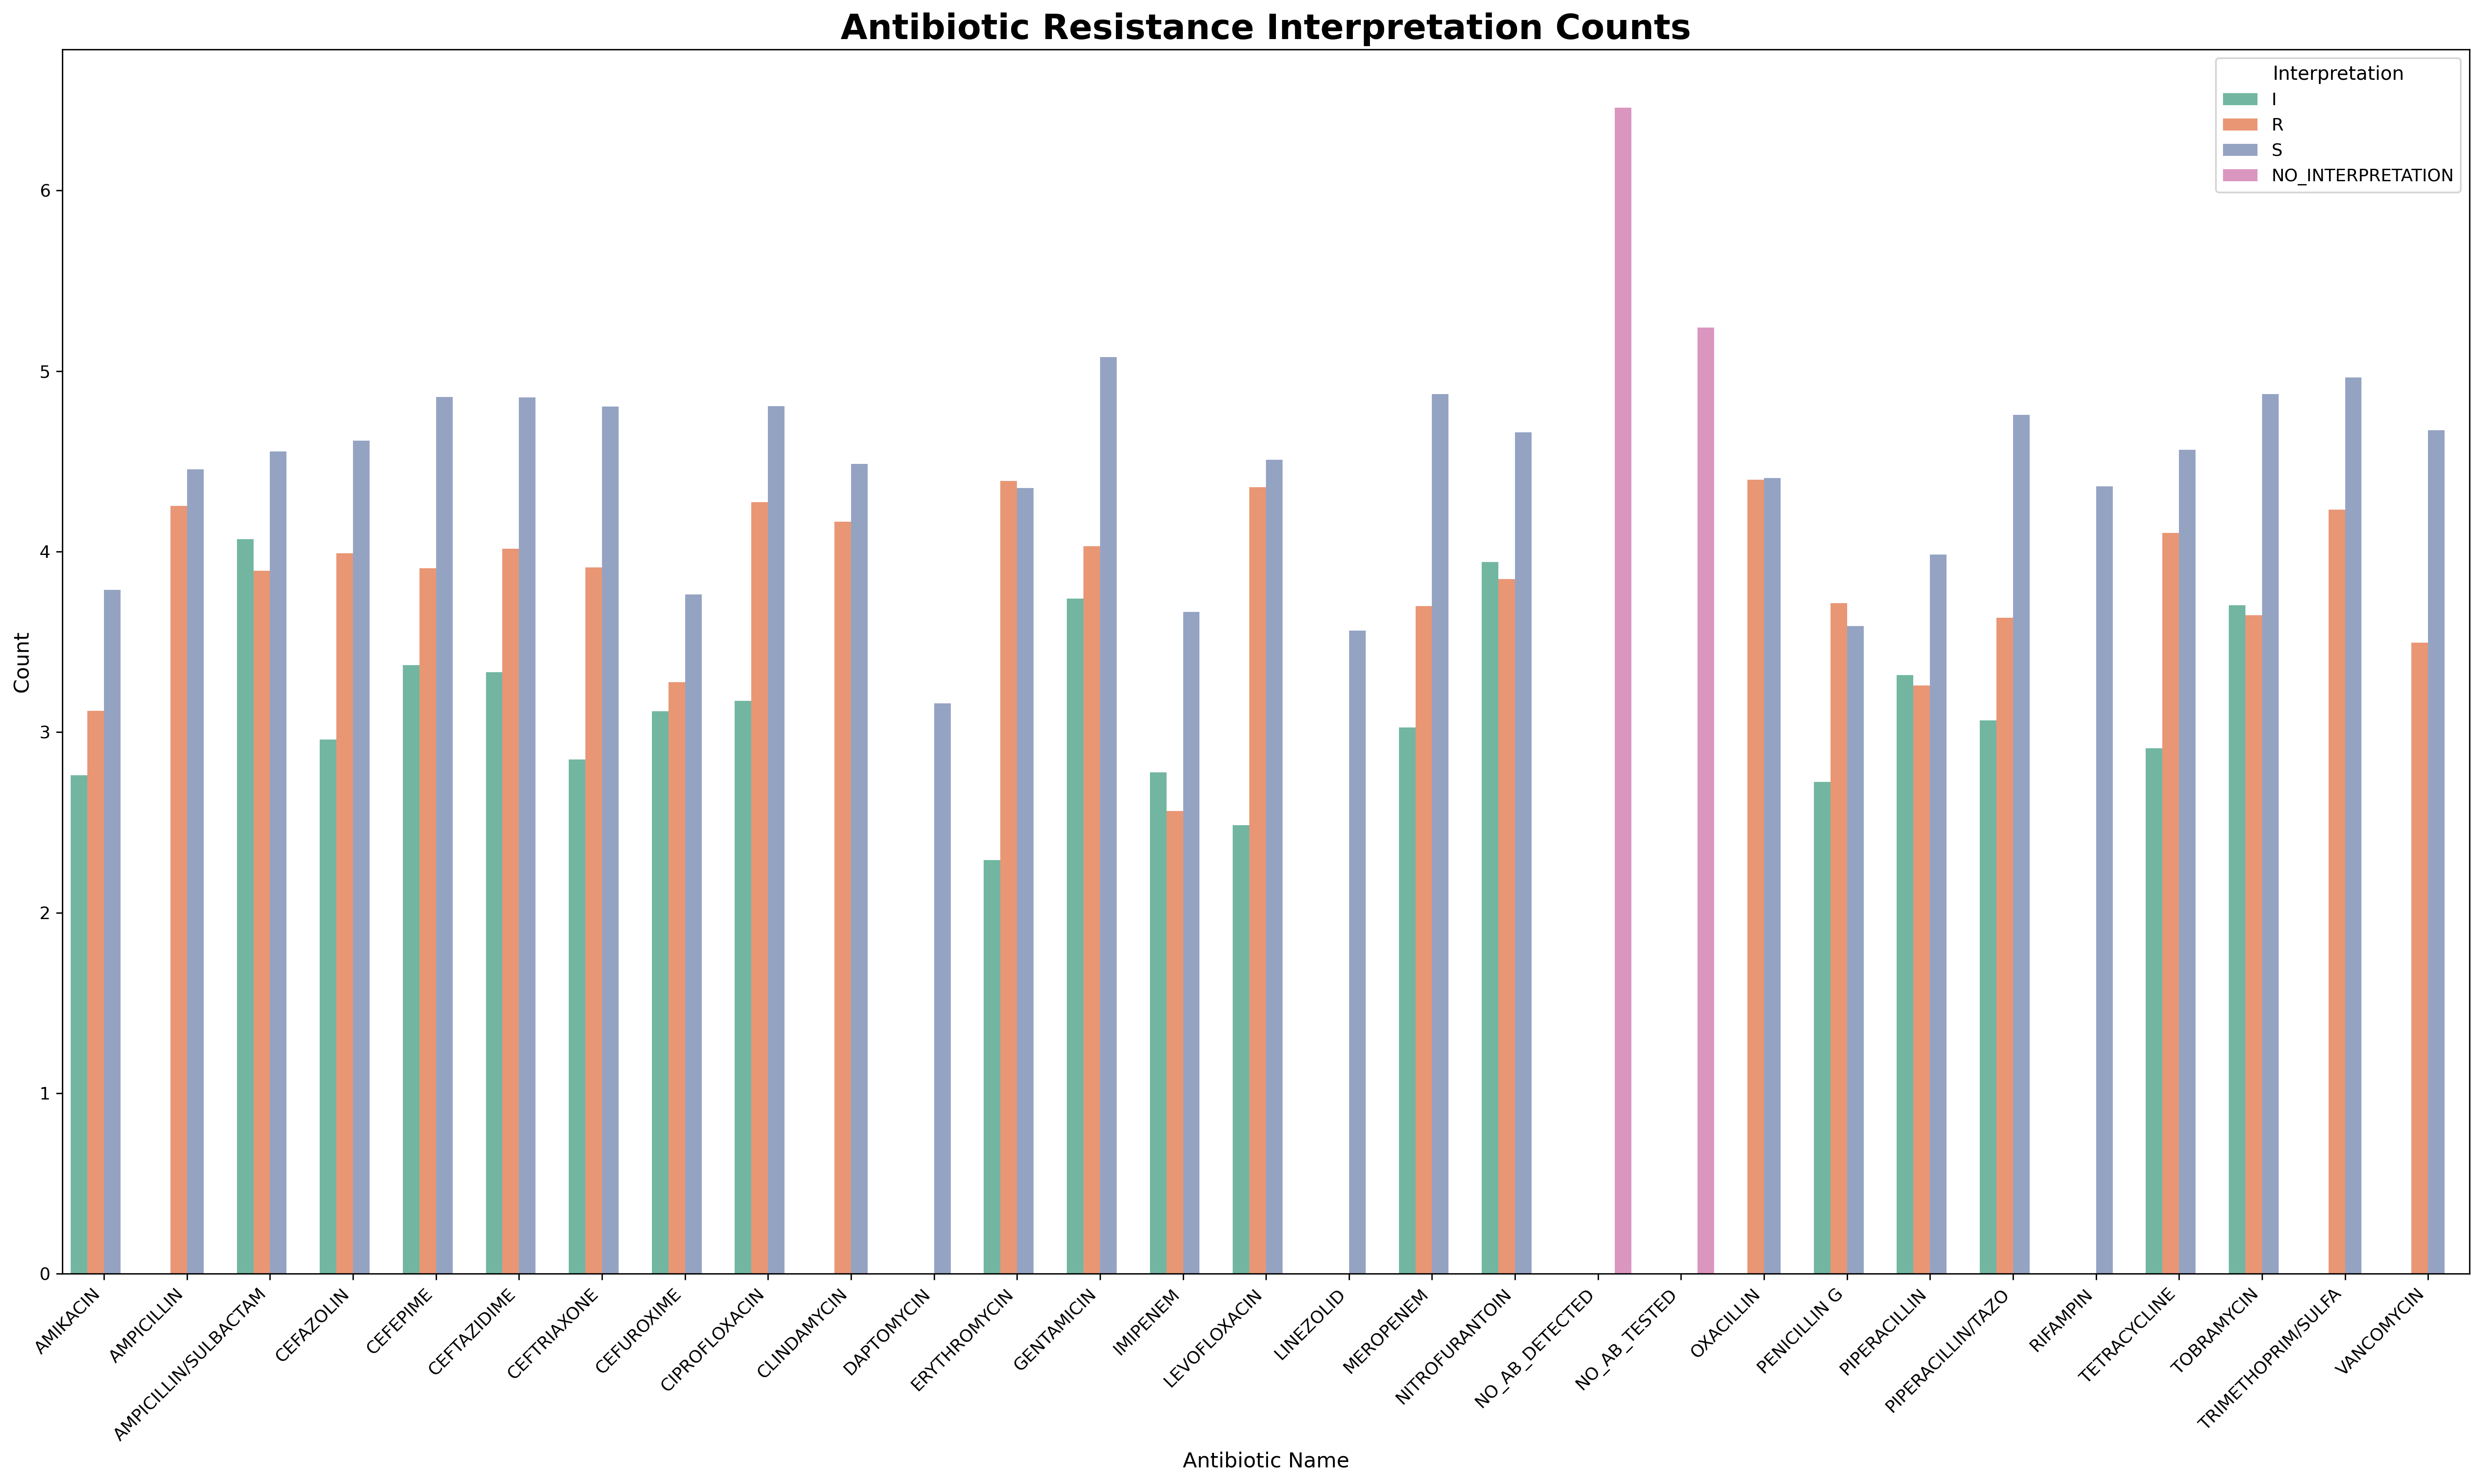

In [79]:
# Get the counts
resistant_counts = np.log10(joined_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

# Calculate average count for each interpretation to determine order
interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

# Create the plot
fig, ax = plt.subplots(figsize=(20,12), dpi=300)

# Create grouped barplot with sorted hue order
sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

# Customize the plot
ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

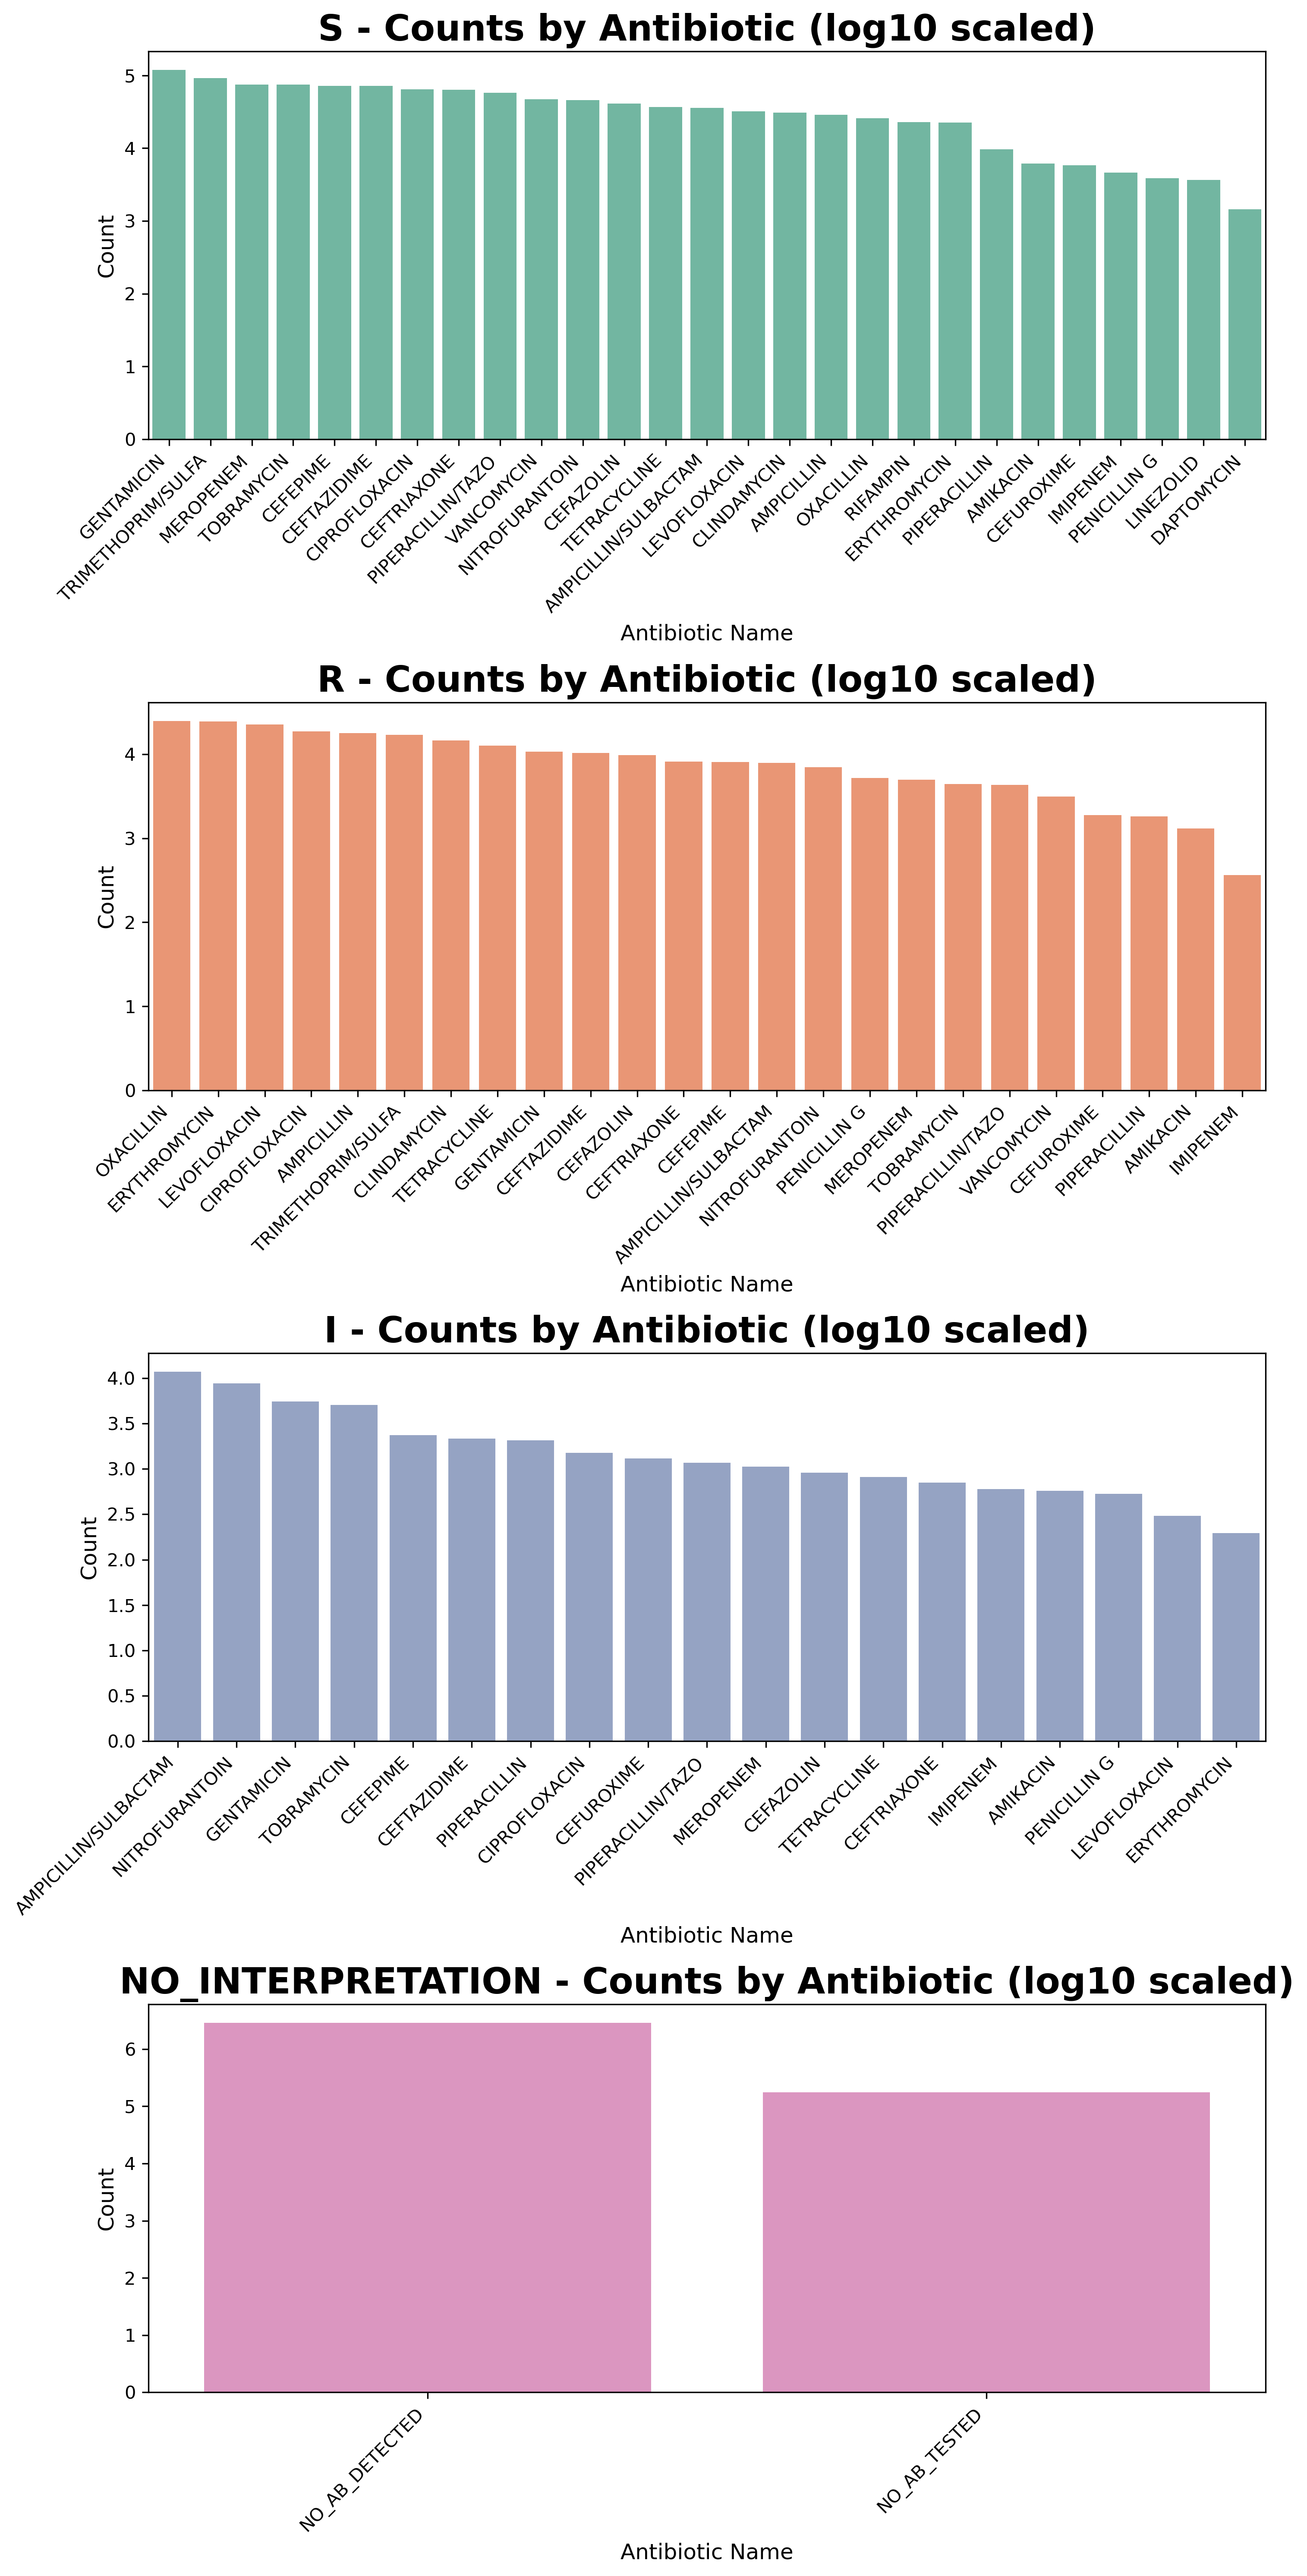

In [80]:
# Get unique interpretations
interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots - one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  5* n_interpretations), dpi=300)

# Handle case of single interpretation
if n_interpretations == 1:
    axes = [axes]

# Create a plot for each interpretation
for idx, interpretation in enumerate(interpretations):
    # Filter data for this interpretation
    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    # Sort by count in descending order
    subset = subset.sort_values('count', ascending=False)
    
    # Create barplot
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name']  # Explicitly set the order
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    # Rotate x-axis labels
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()